# Africa WEEE: publication results, figures and screening economic valuation

**Status:** publication-facing final synthesis notebook.

This notebook reads their official outputs and produces manuscript figures, headline tables and a transparent screening economic valuation.

## Management interpretation

- **Current informal-management baseline**: screening-level representation of present informal WEEE management conditions in Africa.
- **Formal-treatment counterfactual**: what-if benchmark applying formal treatment to the same WEEE quantity and composition.

These cases are deliberately asymmetric: the formal case is not presented as an observed historical pathway.

## Spatial framing of benefits

1. **Local PM-health benefit (Africa)**  
   Potential reduction in PM-related DALYs under formal treatment × EUR/DALY.

2. **Global climate benefit**  
   Potential reduction in GWP × social cost of carbon.

3. **Global CRM resource / market value**  
   Additional physically recoverable Cu, Ag, Au and Pd × historical international reference prices.

CRM market value is **not** interpreted as income captured in Africa. Where economic value is ultimately retained depends on collection, preprocessing, ownership, exports, refining and trade margins.

## Deliberate exclusions

The economic section is a **partial monetised benefit assessment**, not a complete social cost-benefit analysis. It excludes formal-system CAPEX/OPEX, collection and enforcement costs, informal-sector livelihood effects, and environmental credits from avoided primary mining/refining.

Accordingly, manuscript language should use **potential monetised benefits**, not net benefits or benefit-cost ratios.

In [1]:
# CELL 1 — IMPORTS, PATHS, LABELS, STYLE

from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from matplotlib.colors import PowerNorm

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

PROJECT_DIR = Path.cwd()
ACTIVITY_DIR = PROJECT_DIR / "ewaste_activity_results" / "v2_electricity_baseline"
LCA_CANDIDATES = [PROJECT_DIR / "03_Africa_LCA_scaling_outputs", PROJECT_DIR]
CRM_DIR = PROJECT_DIR / "05_CRM_recovery_outputs" / "v3_final"

FIG_DIR = PROJECT_DIR / "06_paper_outputs" / "figures"
TABLE_DIR = PROJECT_DIR / "06_paper_outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

ACTIVITY_FILES = {
    "ewaste": ACTIVITY_DIR / "ewaste_generated_country_year_product.csv",
    "pom": ACTIVITY_DIR / "pom_country_year_product.csv",
    "country_year": ACTIVITY_DIR / "ewaste_generated_country_year.csv",
    "meta": ACTIVITY_DIR / "run_metadata.json",
}
LCA_REQUIRED = [
    "africa_year_lcia.csv",
    "country_year_lcia.csv",
    "country_year_product_lcia_long.csv",
    "country_year_formal_informal_comparison.csv",
    "product_group_lcia_coefficients.csv",
    "run_metadata_03.json",
]
LCA_DIR = next((p for p in LCA_CANDIDATES if all((p/f).exists() for f in LCA_REQUIRED)), None)

CRM_FILES = {
    "available_cumulative": CRM_DIR / "crm_available_cumulative.csv",
    "available_year": CRM_DIR / "crm_available_africa_year.csv",
    "recovery_year": CRM_DIR / "crm_recovery_africa_year.csv",
    "additional_recovery": CRM_DIR / "crm_forgone_recovery_cumulative.csv",
    "meta": CRM_DIR / "run_metadata_05.json",
}

for label, path in ACTIVITY_FILES.items():
    assert path.exists(), f"Missing Notebook 02 output ({label}): {path}"
assert LCA_DIR is not None, "Could not locate Notebook 03 outputs."
for label, path in CRM_FILES.items():
    assert path.exists(), f"Missing Notebook 05 output ({label}): {path}"

S_CURRENT = "Africa informal"
S_FORMAL = "Africa formal"
LABEL_CURRENT = "Current informal-management baseline"
LABEL_FORMAL = "Formal-treatment counterfactual"

PRODUCT_ORDER = [
    "Cooling equipment","Lighting","Other equipment","Large household appliances",
    "Screens","Small household appliances","Ventilation equipment",
    "Telecom equipment","IT equipment","Electric tools",
]
PRODUCT_COLORS = {p: plt.get_cmap("tab10")(i % 10) for i,p in enumerate(PRODUCT_ORDER)}

COL_CURRENT = "#D95F02"
COL_FORMAL = "#1B9E77"

plt.rcParams.update({
    "font.family":"sans-serif",
    "font.size":10,
    "axes.titlesize":11,
    "axes.labelsize":10,
    "axes.spines.top":False,
    "axes.spines.right":False,
    "figure.dpi":130,
    "savefig.dpi":600,
})

print("Activity:", ACTIVITY_DIR)
print("LCA:", LCA_DIR)
print("CRM:", CRM_DIR)

Activity: C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\ewaste_activity_results\v2_electricity_baseline
LCA: C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\03_Africa_LCA_scaling_outputs
CRM: C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\05_CRM_recovery_outputs\v3_final


In [2]:
# CELL 2 — LOAD OFFICIAL OUTPUTS + PROVENANCE

ewaste = pd.read_csv(ACTIVITY_FILES["ewaste"])
pom = pd.read_csv(ACTIVITY_FILES["pom"])
activity_country_year = pd.read_csv(ACTIVITY_FILES["country_year"])

africa_lcia = pd.read_csv(LCA_DIR / "africa_year_lcia.csv")
country_lcia = pd.read_csv(LCA_DIR / "country_year_lcia.csv")
product_lcia = pd.read_csv(LCA_DIR / "country_year_product_lcia_long.csv")
comparison = pd.read_csv(LCA_DIR / "country_year_formal_informal_comparison.csv")

crm_available_cum = pd.read_csv(CRM_FILES["available_cumulative"])
crm_available_year = pd.read_csv(CRM_FILES["available_year"])
crm_recovery_year = pd.read_csv(CRM_FILES["recovery_year"])
crm_additional = pd.read_csv(CRM_FILES["additional_recovery"])

with open(ACTIVITY_FILES["meta"], encoding="utf-8") as f: meta02 = json.load(f)
with open(LCA_DIR / "run_metadata_03.json", encoding="utf-8") as f: meta03 = json.load(f)
with open(CRM_FILES["meta"], encoding="utf-8") as f: meta05 = json.load(f)

assert meta02.get("apply_electricity_adjustment") is True
assert set(africa_lcia["Scenario"].unique()) == {S_CURRENT, S_FORMAL}
assert set(product_lcia["Method"].unique()) == {"GWP", "PM_formation"}
assert meta03.get("avoided_primary_production_credits_included") is False
assert meta03.get("monetization_included") is False
assert meta05.get("prices_included") is False
assert meta05.get("monetization_included") is False
assert set(meta05.get("crm_codes_with_recovery_scenarios", [])) == {"Ag","Au","Cu","Pd"}

YEARS = sorted(ewaste["Year"].astype(int).unique())
YEAR0, YEAR1 = min(YEARS), max(YEARS)

print(f"Period: {YEAR0}–{YEAR1}")
print(f"Countries: {ewaste['ISO3'].nunique()}")
print("✓ Provenance checks passed")

Period: 2014–2024
Countries: 54
✓ Provenance checks passed


# Figure 1 — Magnitude and evolution of the flow

A deliberately simple opening figure:
- **A:** EEE imports/POM by product group.
- **B:** modelled WEEE generation by product group.

The Africa map is separated into Figure 2 so that geography has enough visual space.

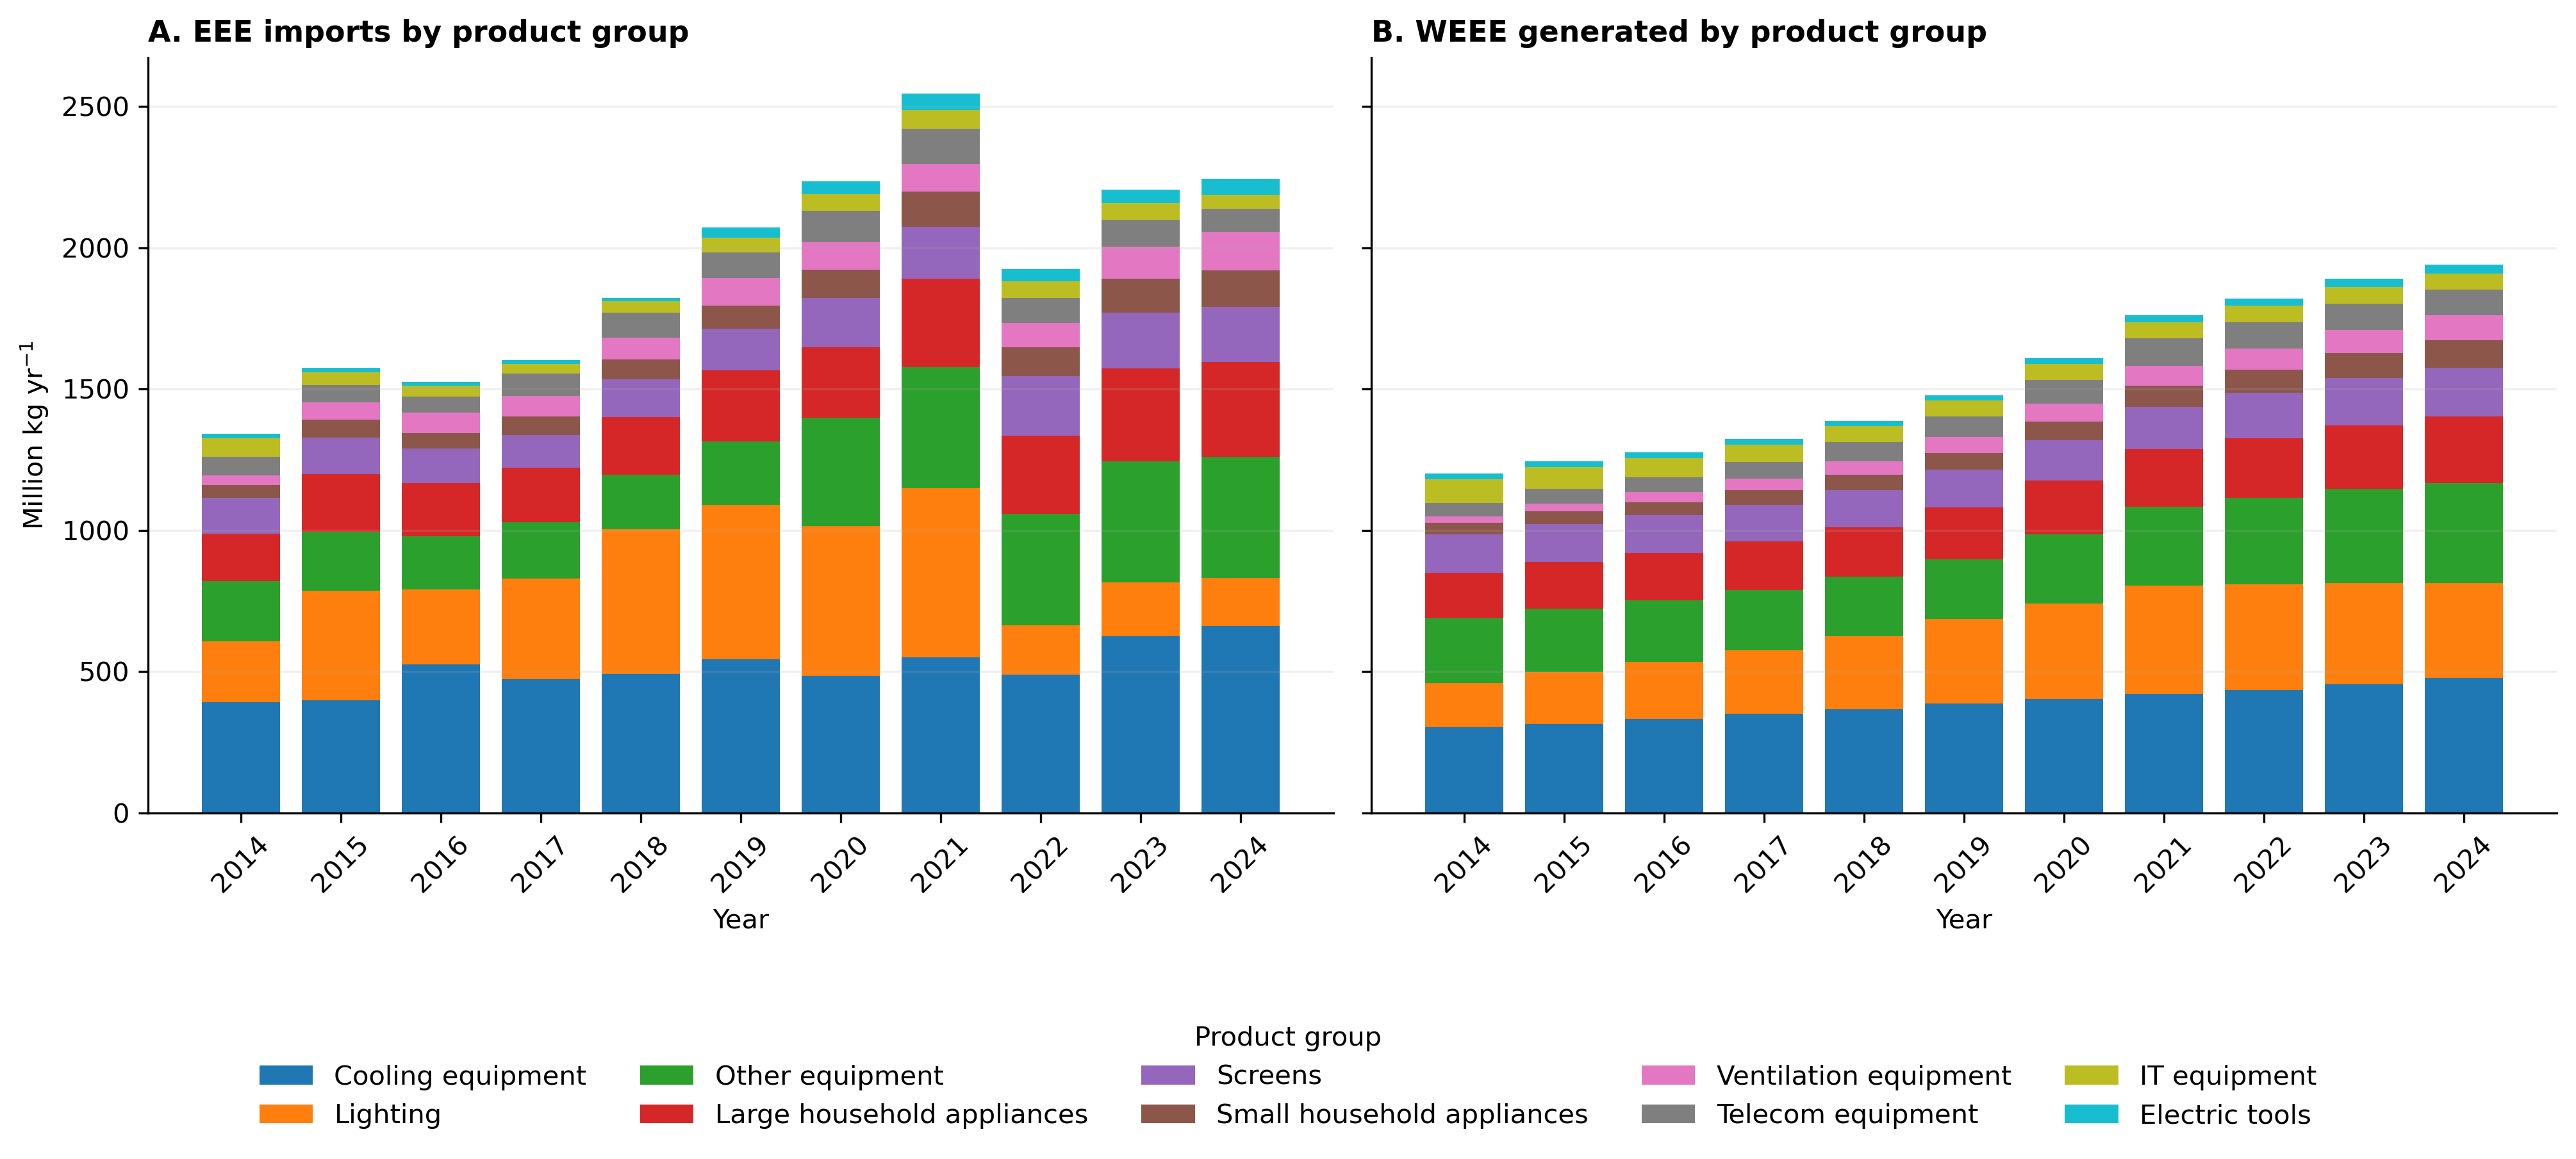

In [3]:
# CELL 3 — FIGURE 1: FLOW ONLY

pom_plot = pom.groupby(["Year","ProductGroup"], as_index=False)["POM_kg"].sum()
ew_plot = ewaste.groupby(["Year","ProductGroup"], as_index=False)["EWasteGenerated_kg"].sum()

pom_wide = pom_plot.pivot(index="Year",columns="ProductGroup",values="POM_kg").fillna(0)/1e6
ew_wide = ew_plot.pivot(index="Year",columns="ProductGroup",values="EWasteGenerated_kg").fillna(0)/1e6

order = [p for p in PRODUCT_ORDER if p in ew_wide.columns]
order += [p for p in ew_wide.columns if p not in order]

fig, axes = plt.subplots(1,2,figsize=(13.5,5.5),dpi=300,sharey=True)

for ax, wide, title in [
    (axes[0],pom_wide,"A. EEE imports by product group"),
    (axes[1],ew_wide,"B. WEEE generated by product group")
]:
    bottom=np.zeros(len(wide))
    for p in order:
        vals=wide[p].values if p in wide.columns else np.zeros(len(wide))
        ax.bar(wide.index.astype(str),vals,bottom=bottom,label=p,
               color=PRODUCT_COLORS.get(p),width=0.78)
        bottom += vals
    ax.set_title(title,loc="left",weight="bold")
    ax.set_xlabel("Year")
    ax.tick_params(axis="x",rotation=45)
    ax.grid(axis="y",alpha=.18)

axes[0].set_ylabel("Million kg yr$^{-1}$")

handles,labels=axes[1].get_legend_handles_labels()
fig.legend(handles,labels,title="Product group",ncol=5,
           loc="lower center",bbox_to_anchor=(.5,-.10),frameon=False)

plt.tight_layout(rect=[0,.08,1,1])
plt.savefig(FIG_DIR/"Figure1_EEE_WEEE_flow.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure1_EEE_WEEE_flow.pdf",bbox_inches="tight")
plt.show()

# Figure 2 — Geography of WEEE generation

A full-size Africa map showing WEEE generated in the final observation year. This is kept separate from Figure 1 to preserve legibility and give the geographic result its own message.

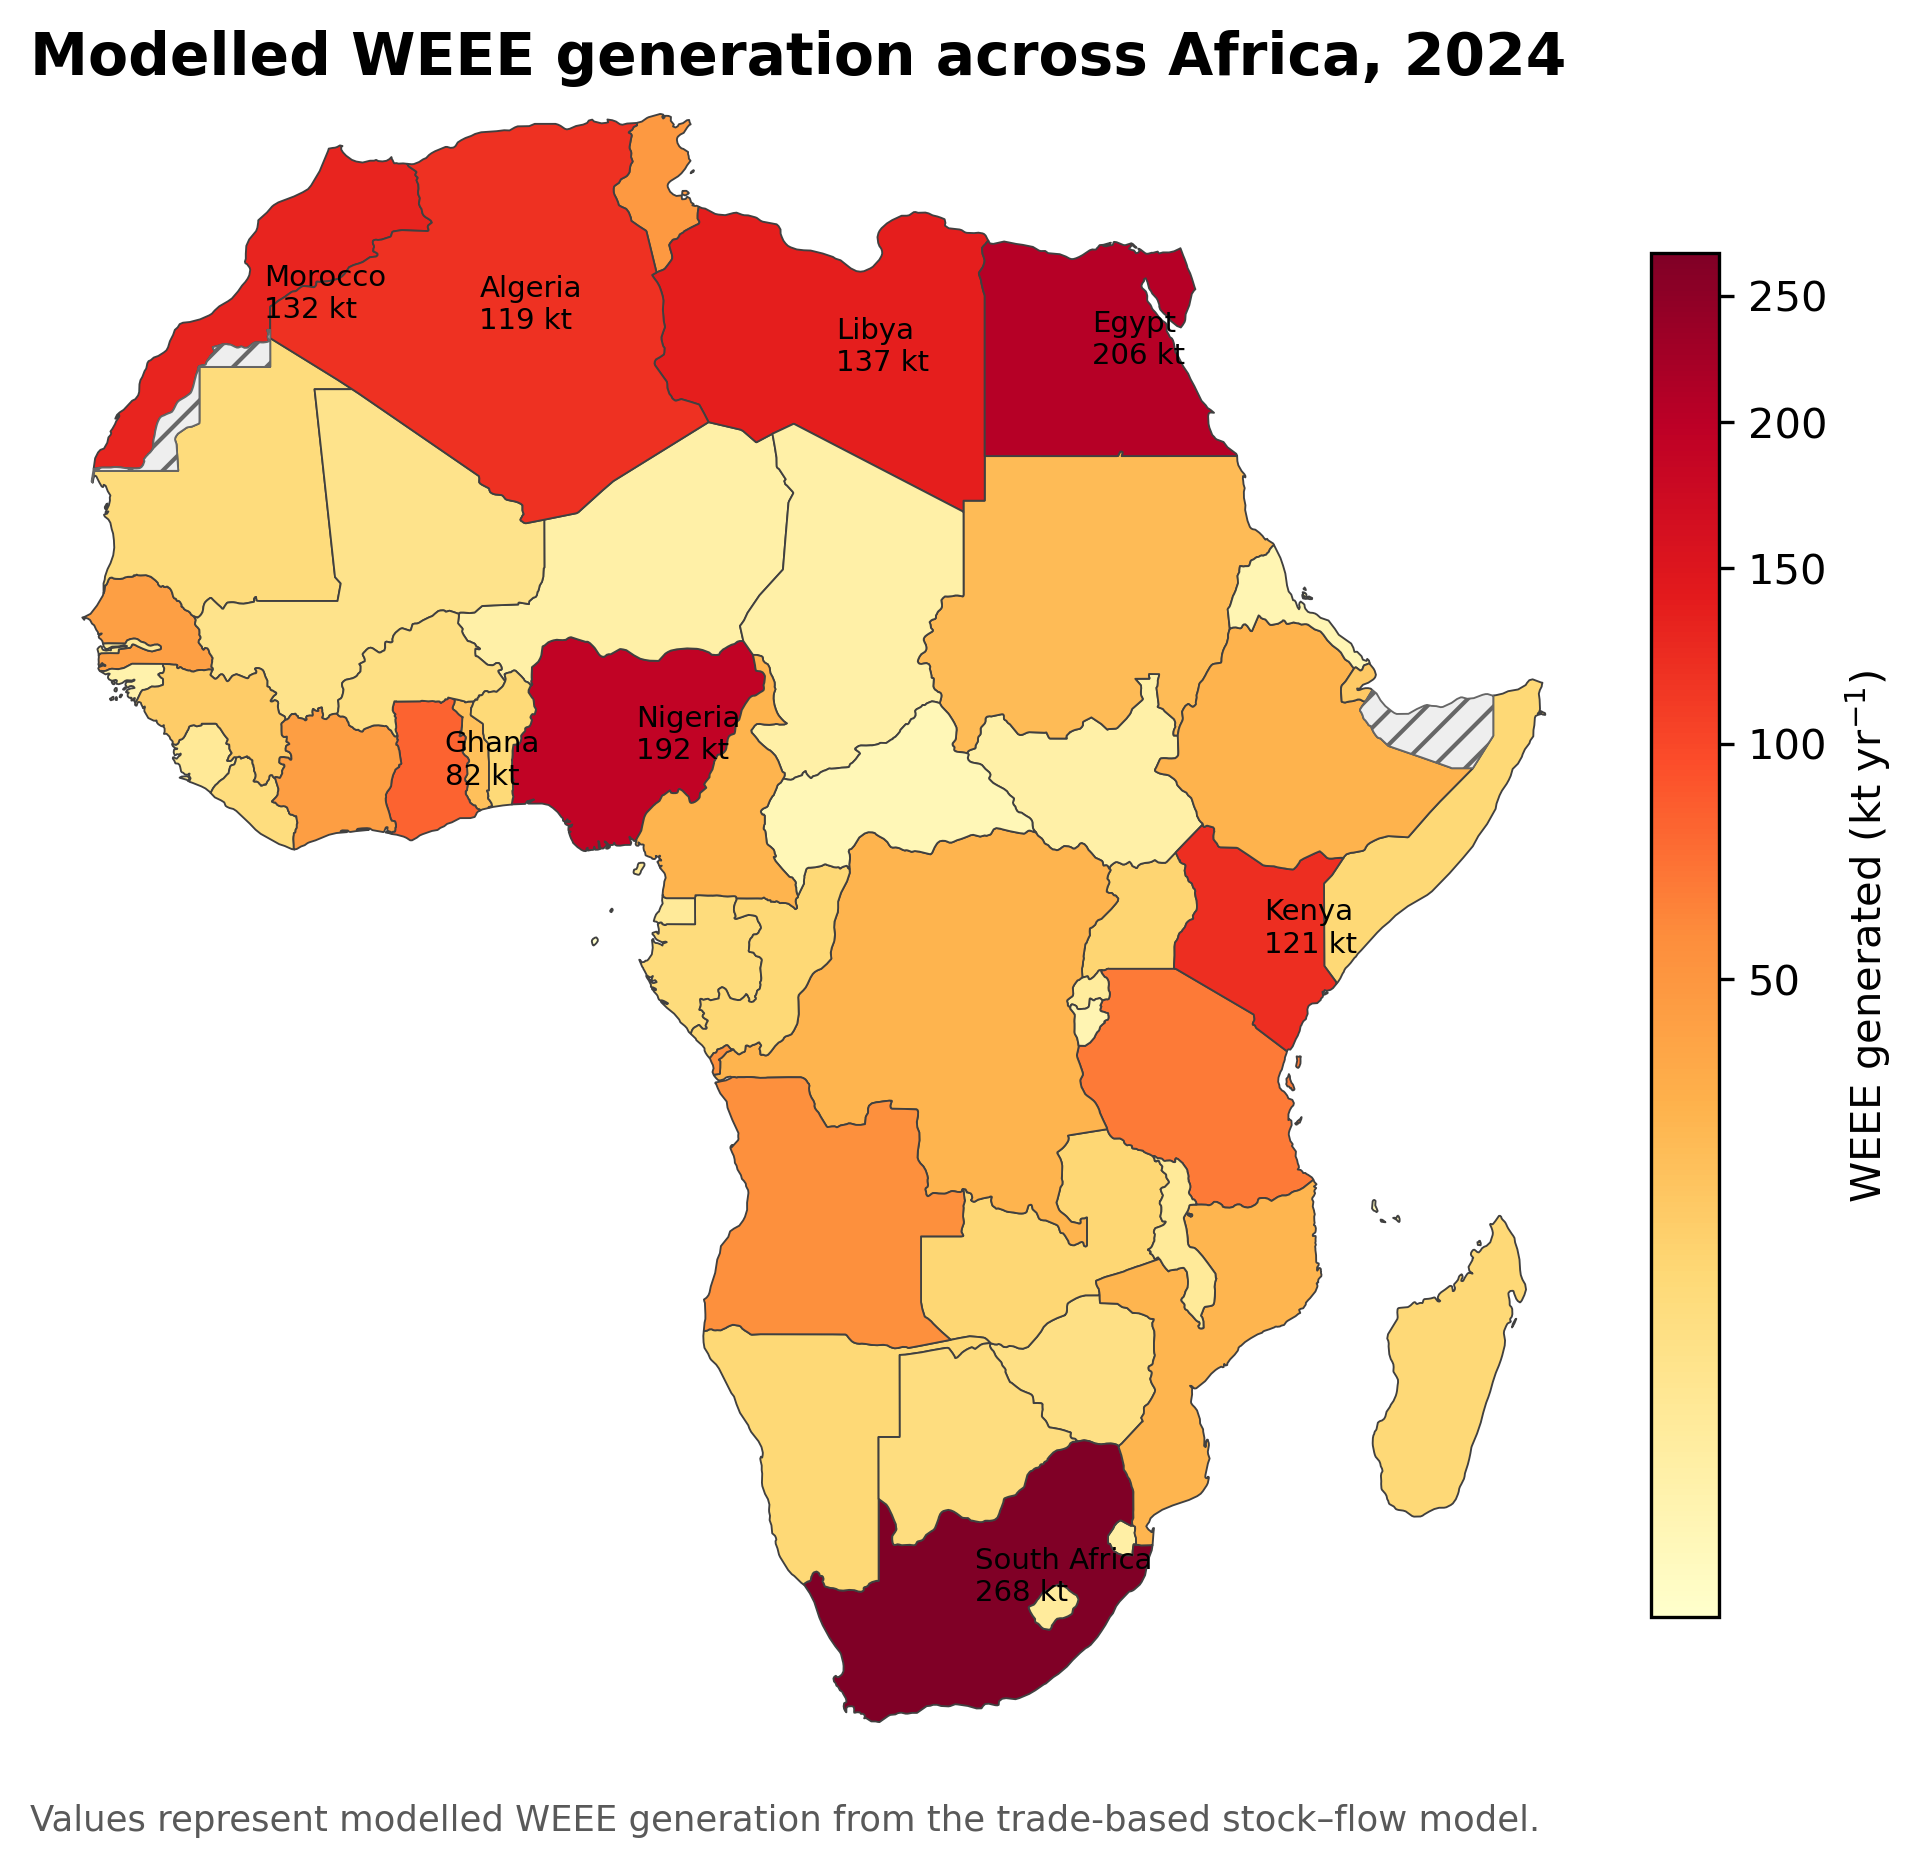

In [4]:
# CELL 4 — FIGURE 2: AFRICA WEEE MAP

map_data = (
    ewaste[ewaste["Year"]==YEAR1]
    .groupby(["ISO3","Country"],as_index=False)["EWasteGenerated_kg"].sum()
)
map_data["ewaste_kt"]=map_data["EWasteGenerated_kg"]/1e6

fig,ax=plt.subplots(figsize=(8.2,8.2),dpi=300)

try:
    import geopandas as gpd
    NE_URL="https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
    world=gpd.read_file(NE_URL)

    world["iso3"]=np.nan
    for c in [c for c in ["ISO_A3","ADM0_A3","SOV_A3"] if c in world.columns]:
        world["iso3"]=world["iso3"].fillna(world[c].replace("-99",np.nan))

    africa=world[world["CONTINENT"]=="Africa"].copy()
    africa=africa.merge(map_data,left_on="iso3",right_on="ISO3",how="left")

    valid=africa["ewaste_kt"].dropna()
    norm=PowerNorm(gamma=.45,vmin=max(valid.min(),1e-12),vmax=valid.max())

    africa.plot(column="ewaste_kt",cmap="YlOrRd",norm=norm,
                linewidth=.45,edgecolor=".25",ax=ax,
                missing_kwds={"color":"#eeeeee","edgecolor":".4","hatch":"///"})

    top=africa.dropna(subset=["ewaste_kt"]).nlargest(8,"ewaste_kt").copy()
    pts=top.to_crs(3857).representative_point().to_crs(4326)
    top["_x"],top["_y"]=pts.x,pts.y
    for _,r in top.iterrows():
        label=r["Country"] if pd.notna(r["Country"]) else r["iso3"]
        ax.text(r["_x"]+.6,r["_y"]+.4,
                f"{label}\n{r['ewaste_kt']:.0f} kt",
                fontsize=7,ha="left",va="center")

    sm=mpl.cm.ScalarMappable(cmap="YlOrRd",norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=.72,pad=.015)
    cb.set_label("WEEE generated (kt yr$^{-1}$)")

    ax.set_xlim(-20,55); ax.set_ylim(-37,38); ax.axis("off")
    ax.set_title(f"Modelled WEEE generation across Africa, {YEAR1}",
                 loc="left",fontsize=14,weight="bold")
    ax.text(0,-.035,
            "Values represent modelled WEEE generation from the trade-based stock–flow model.",
            transform=ax.transAxes,fontsize=8.5,color=".35")

except Exception as exc:
    ax.text(.5,.5,f"Map not rendered:\n{exc}",ha="center",va="center")
    ax.axis("off")
    warnings.warn(str(exc))

plt.savefig(FIG_DIR/"Figure2_Africa_WEEE_map.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure2_Africa_WEEE_map.pdf",bbox_inches="tight")
plt.show()

# Figure 3 — Local health burden vs global climate burden

This figure carries the central conceptual result of the paper.

- **Local:** PM-health burden is assigned to the African countries where current informal WEEE treatment occurs.
- **Global:** climate damages from GHG emissions are treated as global externalities.

The formal-treatment case is a counterfactual benchmark, not a second observed historical scenario.

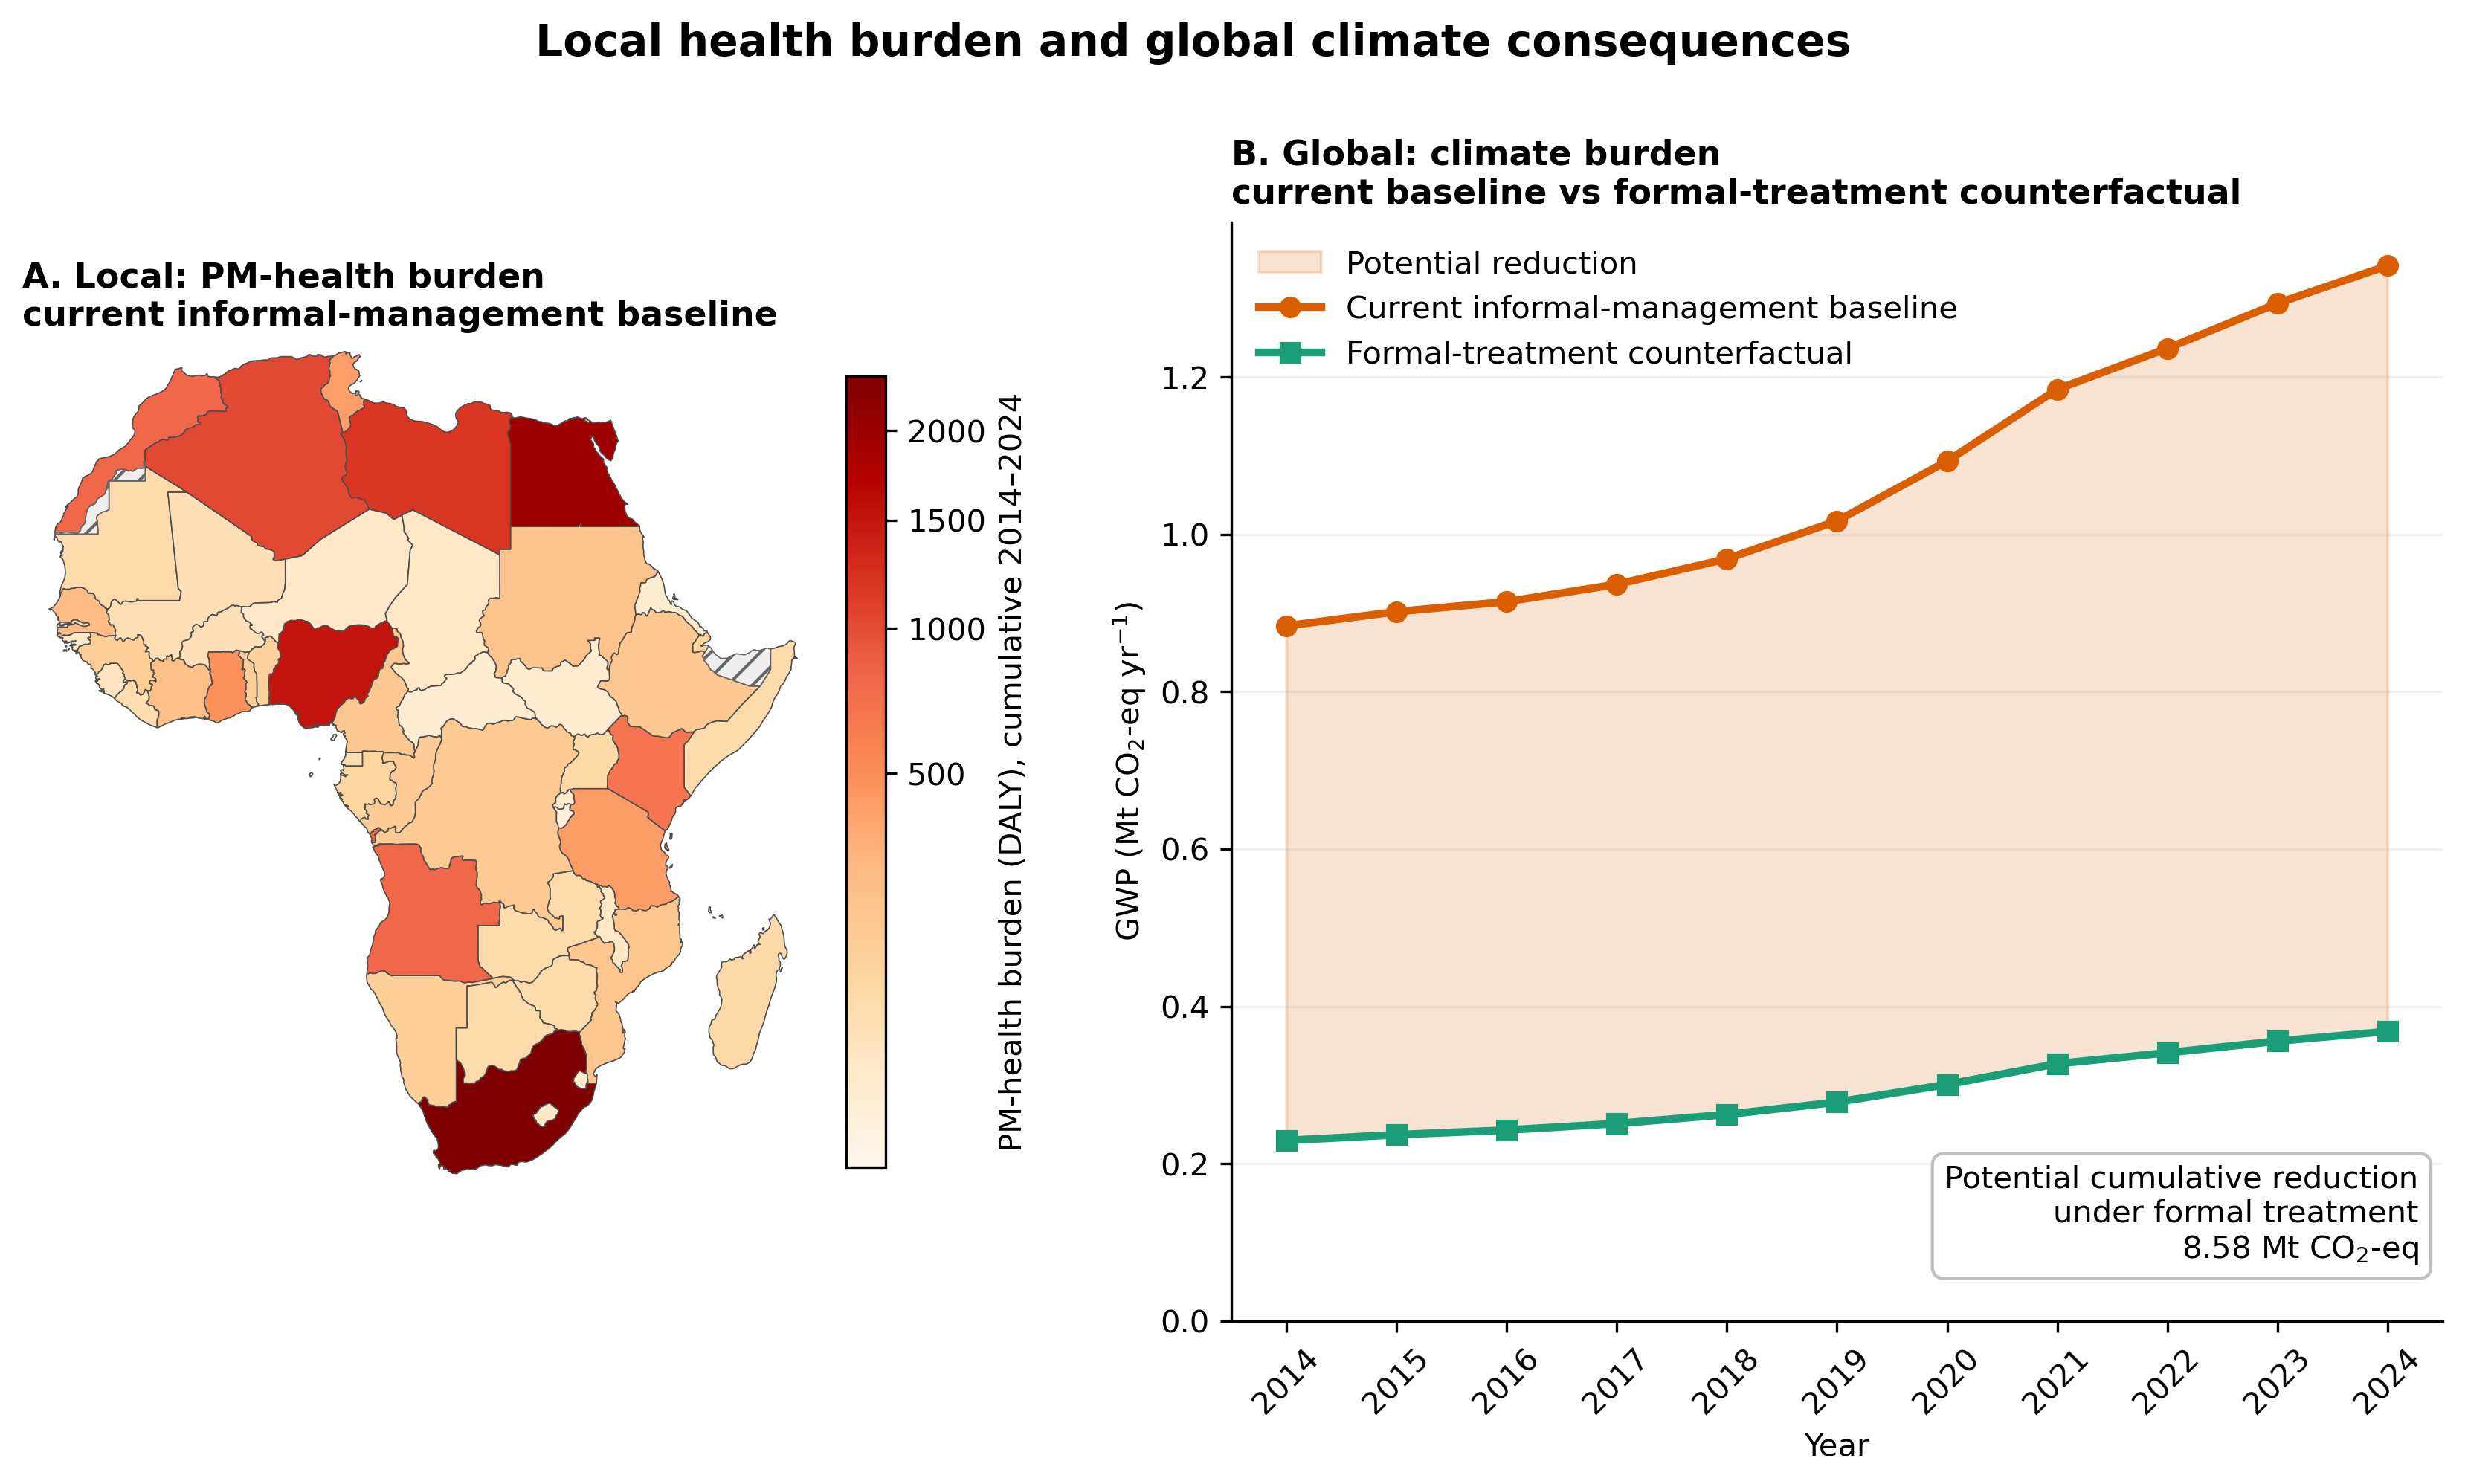

In [5]:
# CELL 5 — FIGURE 3: LOCAL HEALTH + GLOBAL CLIMATE

health = (
    country_lcia[country_lcia["Scenario"]==S_CURRENT]
    .groupby(["ISO3","Country"],as_index=False)["PM_DALY"].sum()
    .rename(columns={"PM_DALY":"DALY"})
)
gwp=(africa_lcia.pivot(index="Year",columns="Scenario",values="GWP_kgCO2eq").sort_index()/1e9)
gwp_delta=float((gwp[S_CURRENT]-gwp[S_FORMAL]).sum())

fig=plt.figure(figsize=(14,6.4),dpi=300)
gs=gridspec.GridSpec(1,2,width_ratios=[1,1.25],wspace=.22)
ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[0,1])

try:
    import geopandas as gpd
    NE_URL="https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
    world=gpd.read_file(NE_URL)
    world["iso3"]=np.nan
    for c in [c for c in ["ISO_A3","ADM0_A3","SOV_A3"] if c in world.columns]:
        world["iso3"]=world["iso3"].fillna(world[c].replace("-99",np.nan))
    africa=world[world["CONTINENT"]=="Africa"].copy().merge(
        health,left_on="iso3",right_on="ISO3",how="left"
    )
    valid=africa["DALY"].dropna()
    norm=PowerNorm(gamma=.45,vmin=max(valid.min(),1e-12),vmax=valid.max())
    africa.plot(column="DALY",cmap="OrRd",norm=norm,linewidth=.4,
                edgecolor=".3",ax=ax1,
                missing_kwds={"color":"#eeeeee","edgecolor":".4","hatch":"///"})
    sm=mpl.cm.ScalarMappable(cmap="OrRd",norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax1,shrink=.72,pad=.01)
    cb.set_label(f"PM-health burden (DALY), cumulative {YEAR0}–{YEAR1}")
    ax1.set_xlim(-20,55); ax1.set_ylim(-37,38); ax1.axis("off")
except Exception as exc:
    ax1.text(.5,.5,str(exc),ha="center",va="center"); ax1.axis("off")

ax1.set_title("A. Local: PM-health burden\ncurrent informal-management baseline",
              loc="left",weight="bold")

years=gwp.index.values
cur=gwp[S_CURRENT].values
formal=gwp[S_FORMAL].values
ax2.fill_between(years,formal,cur,where=cur>=formal,
                 color=COL_CURRENT,alpha=.18,label="Potential reduction")
ax2.plot(years,cur,color=COL_CURRENT,lw=2.5,marker="o",label=LABEL_CURRENT)
ax2.plot(years,formal,color=COL_FORMAL,lw=2.5,marker="s",label=LABEL_FORMAL)
ax2.set_ylabel("GWP (Mt CO$_2$-eq yr$^{-1}$)")
ax2.set_xlabel("Year")
ax2.set_xticks(years); ax2.tick_params(axis="x",rotation=45)
ax2.set_ylim(bottom=0); ax2.grid(axis="y",alpha=.18)
ax2.legend(frameon=False)
ax2.text(.98,.05,
         f"Potential cumulative reduction\nunder formal treatment\n{gwp_delta:.2f} Mt CO$_2$-eq",
         transform=ax2.transAxes,ha="right",va="bottom",
         bbox=dict(boxstyle="round,pad=.4",fc="white",ec=".75"))
ax2.set_title("B. Global: climate burden\ncurrent baseline vs formal-treatment counterfactual",
              loc="left",weight="bold")

fig.suptitle("Local health burden and global climate consequences",
             fontsize=14,weight="bold",y=1.02)
plt.savefig(FIG_DIR/"Figure3_local_health_global_climate.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure3_local_health_global_climate.pdf",bbox_inches="tight")
plt.show()

# Figure 4 — Product groups driving current burdens

This figure stays descriptive: it explains which product groups dominate the two environmental indicators under current informal management. Formalisation potential is kept for the economic synthesis rather than adding four competing panels here.

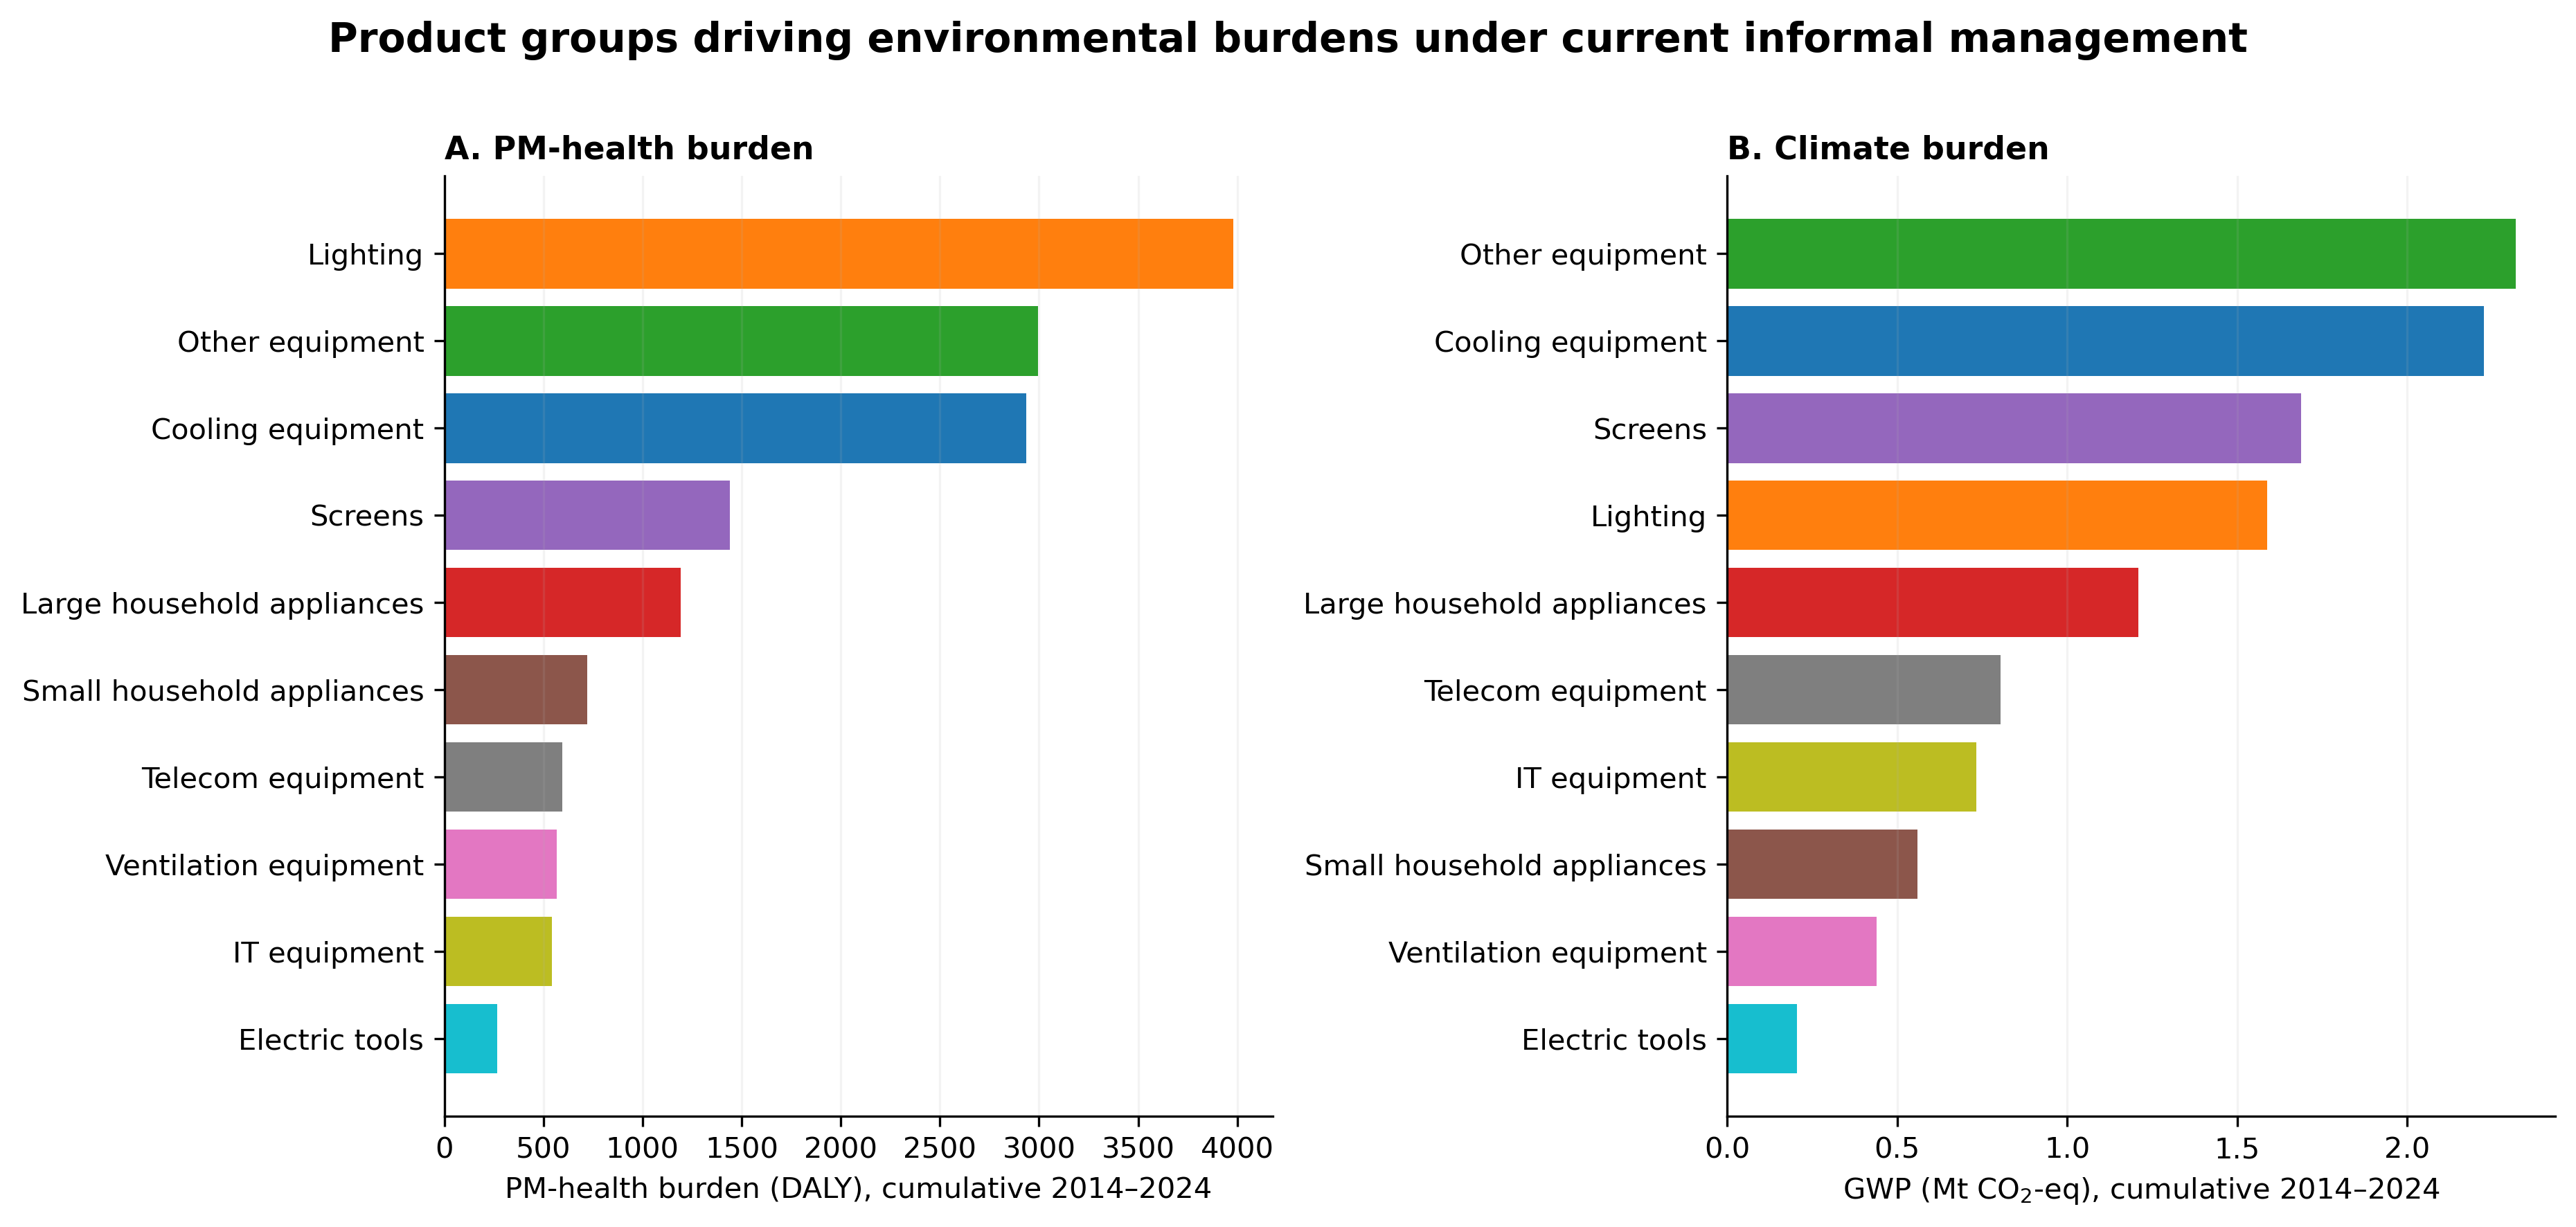

In [6]:
# CELL 6 — FIGURE 4: PRODUCT-GROUP DRIVERS

prod=product_lcia[product_lcia["Scenario"]==S_CURRENT].groupby(
    ["ProductGroup","Method"],as_index=False)["Impact"].sum()

pm=prod[prod["Method"]=="PM_formation"].copy().sort_values("Impact")
gwp_p=prod[prod["Method"]=="GWP"].copy().sort_values("Impact")
gwp_p["Impact_Mt"]=gwp_p["Impact"]/1e9

fig,axes=plt.subplots(1,2,figsize=(12.5,5.8),dpi=300)

axes[0].barh(pm["ProductGroup"],pm["Impact"],
             color=[PRODUCT_COLORS.get(p) for p in pm["ProductGroup"]])
axes[0].set_xlabel(f"PM-health burden (DALY), cumulative {YEAR0}–{YEAR1}")
axes[0].set_title("A. PM-health burden",loc="left",weight="bold")
axes[0].grid(axis="x",alpha=.15)

axes[1].barh(gwp_p["ProductGroup"],gwp_p["Impact_Mt"],
             color=[PRODUCT_COLORS.get(p) for p in gwp_p["ProductGroup"]])
axes[1].set_xlabel(f"GWP (Mt CO$_2$-eq), cumulative {YEAR0}–{YEAR1}")
axes[1].set_title("B. Climate burden",loc="left",weight="bold")
axes[1].grid(axis="x",alpha=.15)

fig.suptitle("Product groups driving environmental burdens under current informal management",
             fontsize=14,weight="bold",y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR/"Figure4_product_drivers.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure4_product_drivers.pdf",bbox_inches="tight")
plt.show()

# Figure 5 — Critical raw materials: physical results only

The CRM figure deliberately **does not use error bars**. Low/high recovery cases are scenario assumptions, not statistical confidence intervals.

- **A:** all 18 tracked CRM physically embedded in WEEE.
- **B:** central estimate of additional recoverable Cu, Ag, Au and Pd under the formal-treatment counterfactual.

The economic value of these materials is introduced separately below.

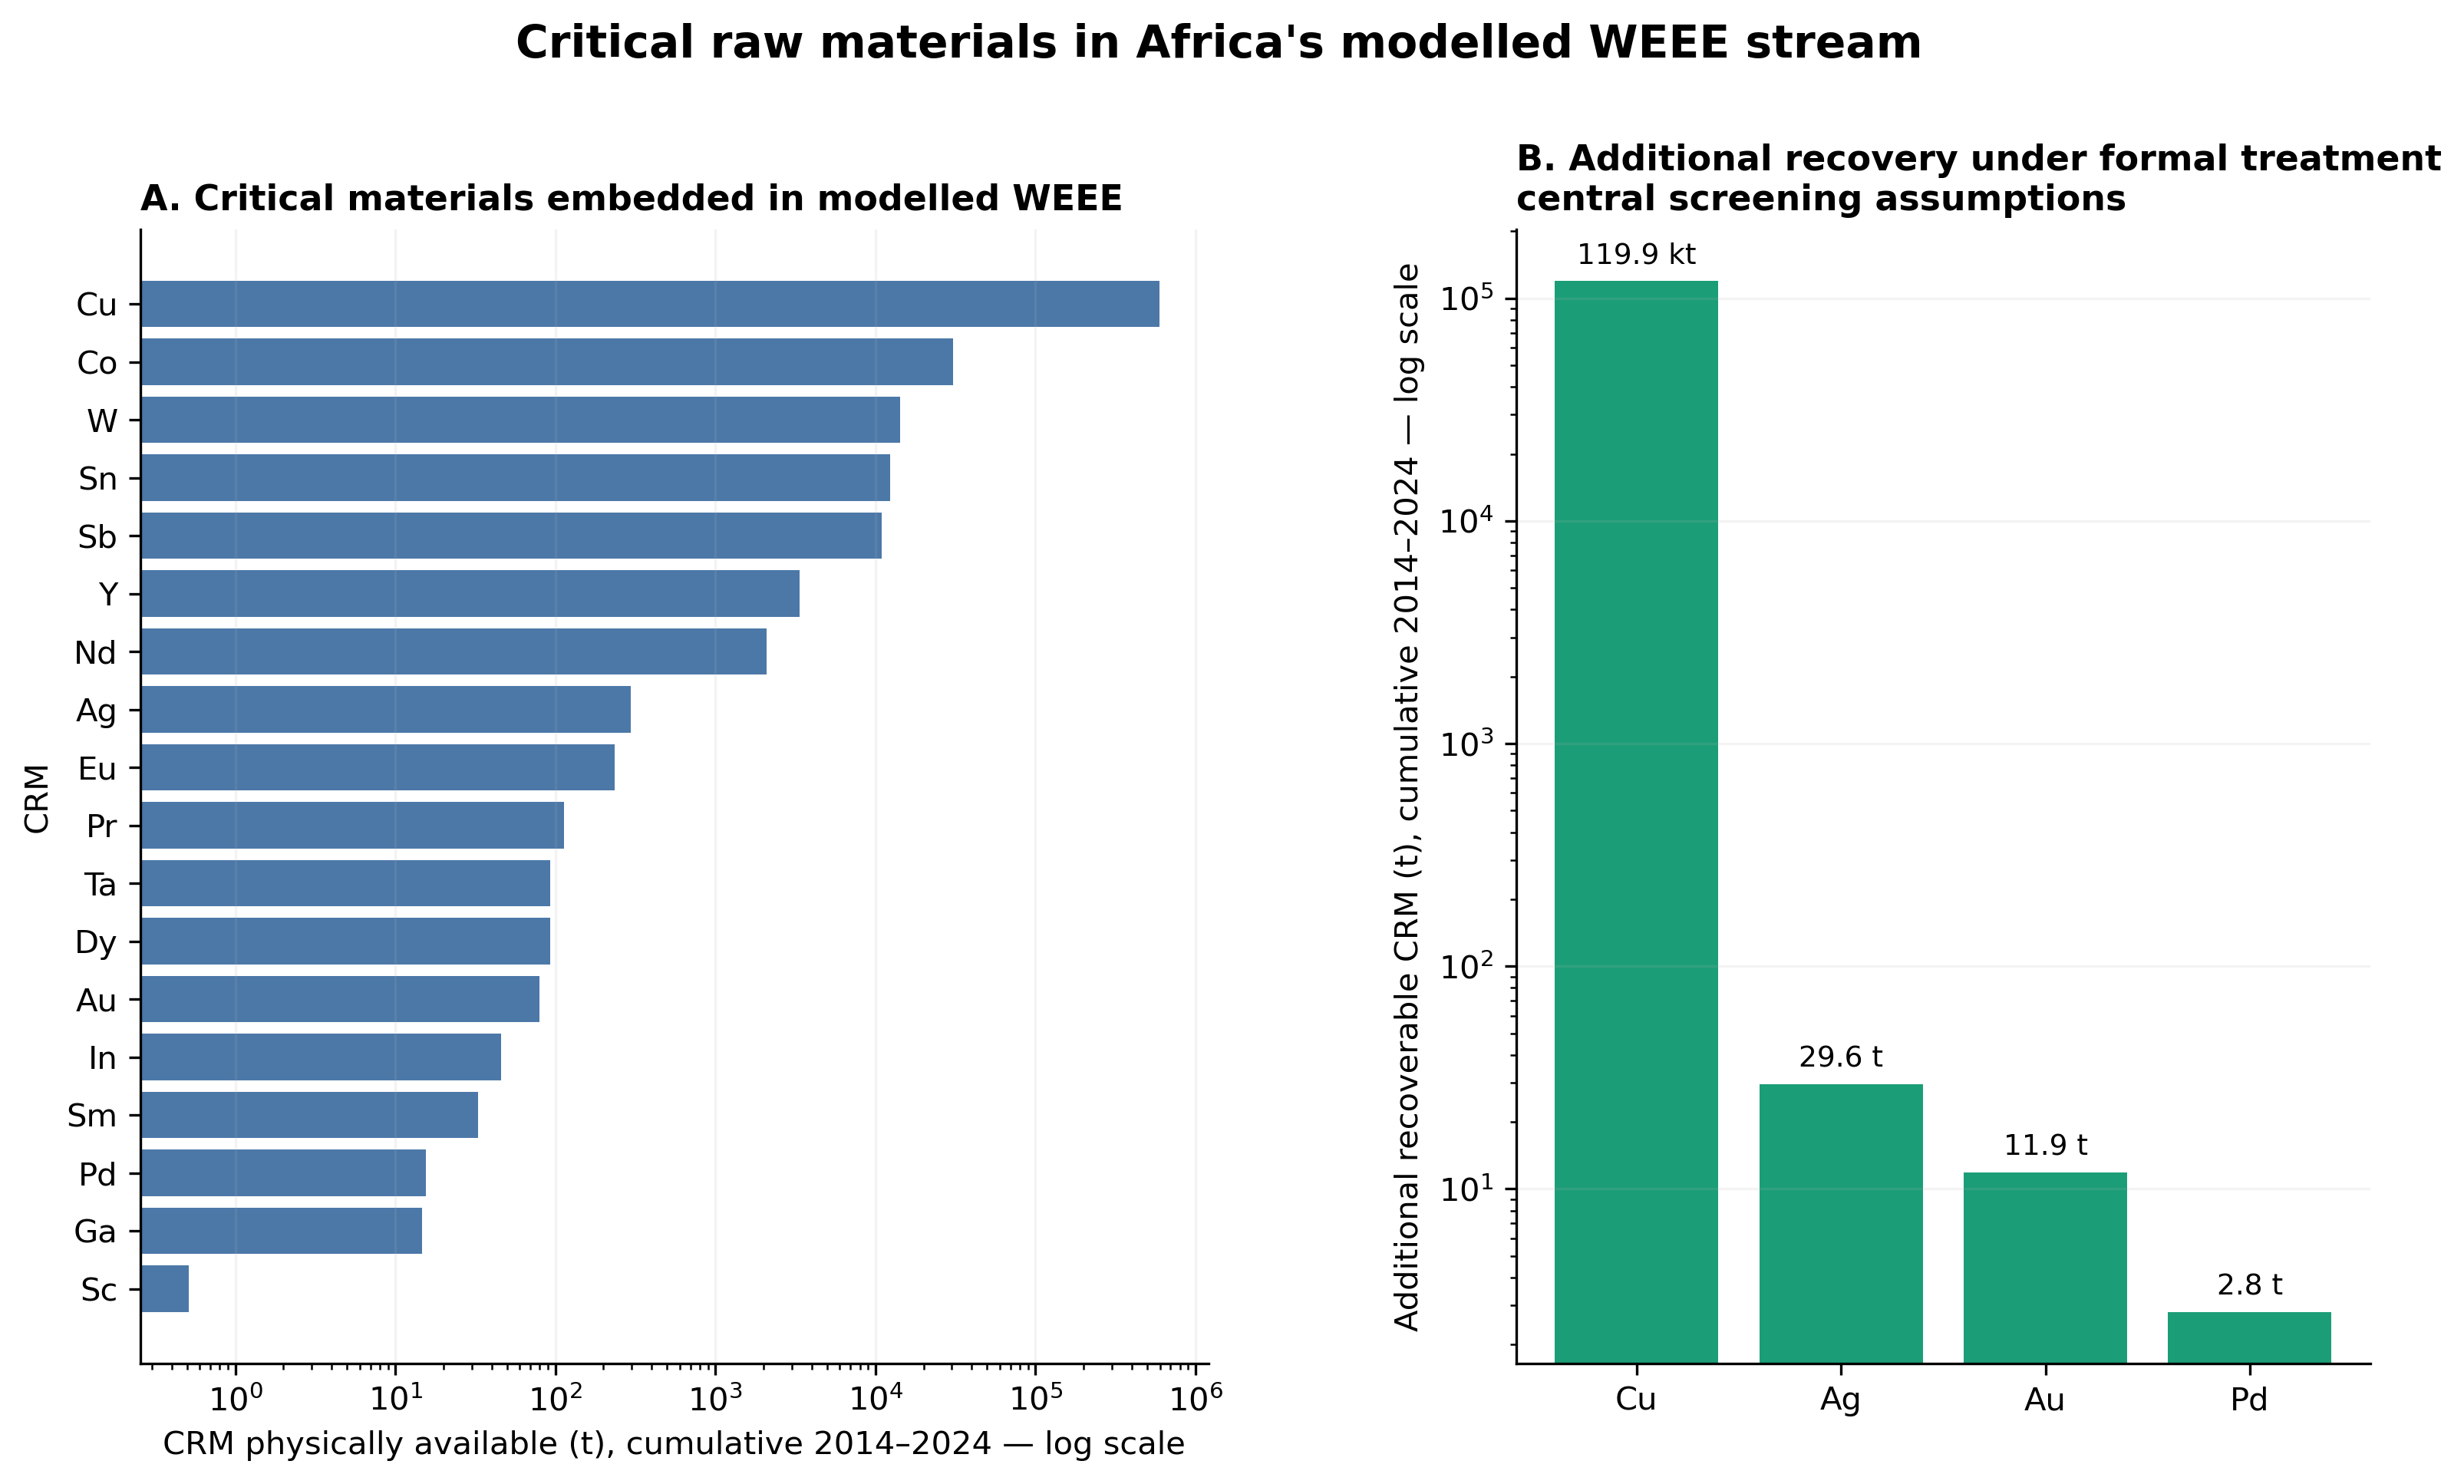

In [7]:
# CELL 7 — FIGURE 5: CRM PHYSICAL RESULTS, NO UNCERTAINTY BARS

crm=crm_available_cum.copy()
crm["available_t"]=crm["CRM_available_kg"]/1000
crm=crm.sort_values("available_t")

add=crm_additional.copy()
add["central_t"]=add["Forgone_central_kg"]/1000

fig=plt.figure(figsize=(12.5,6.4),dpi=300)
gs=gridspec.GridSpec(1,2,width_ratios=[1.25,1],wspace=.32)
ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[0,1])

ax1.barh(crm["element_code"],crm["available_t"],color="#4C78A8")
ax1.set_xscale("log")
ax1.set_xlabel(f"CRM physically available (t), cumulative {YEAR0}–{YEAR1} — log scale")
ax1.set_ylabel("CRM")
ax1.set_title("A. Critical materials embedded in modelled WEEE",loc="left",weight="bold")
ax1.grid(axis="x",alpha=.15)

# Use kg -> t; display Cu in kt and precious metals in t through annotations.
sel=add.set_index("element_code").reindex(["Cu","Ag","Au","Pd"]).reset_index()
# Normalize to tonnes on log axis to keep one honest unit.
ax2.bar(sel["element_code"],sel["central_t"],color=COL_FORMAL)
ax2.set_yscale("log")
ax2.set_ylabel(f"Additional recoverable CRM (t), cumulative {YEAR0}–{YEAR1} — log scale")
ax2.set_title("B. Additional recovery under formal treatment\ncentral screening assumptions",
              loc="left",weight="bold")
ax2.grid(axis="y",alpha=.15)
for i,r in sel.iterrows():
    label=f"{r['central_t']/1000:.1f} kt" if r["central_t"]>=1000 else f"{r['central_t']:.1f} t"
    ax2.text(i,r["central_t"]*1.12,label,ha="center",va="bottom",fontsize=9)

fig.suptitle("Critical raw materials in Africa's modelled WEEE stream",
             fontsize=14,weight="bold",y=1.02)
plt.savefig(FIG_DIR/"Figure5_CRM_physical.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure5_CRM_physical.pdf",bbox_inches="tight")
plt.show()

# Screening economic valuation

## Economic valuation parameters and market-price evidence

The economic layer remains deliberately simple and transparent.

### Local PM-health benefit
`50,000 / 100,000 / 150,000 EUR per DALY`

### Global climate benefit
SCC screening cases:
`50 / 185 / 300 EUR per t CO2-eq`

The central SCC is anchored to Rennert et al. (2022), who report a central social cost of carbon of approximately **US$185/t CO₂**. Here it is used as a configurable screening value rather than as a fully harmonised welfare estimate.

### Global CRM resource / market value

For Cu, Ag and Au, the notebook uses **annual global benchmark commodity prices for 2014–2024**, consistent with the World Bank Pink Sheet / IMF Primary Commodity Price series. These are period-average international market prices, not African local prices.

For Pd, the notebook uses annual average palladium market-price observations compiled from **USGS Mineral Commodity Summaries / USGS platinum-group-metals statistics**.

The central CRM reference price is the **arithmetic mean of annual nominal USD prices over 2014–2024**, converted to EUR/kg with an explicit editable USD→EUR conversion factor.

This is intentionally interpreted as:

> **global resource / market value of additional material recovery**

It is **not** interpreted as income captured in Africa. The geographic capture of this value depends on collection, preprocessing, ownership, export, refining and trade margins.

### Important exclusion

No additional environmental credit is assigned to avoided primary mining, refining or virgin-material production. Those potentially important upstream benefits remain outside the present model boundary.

In [8]:
# CELL 8 — PUBLICATION-FINAL ECONOMIC PARAMETERS
#
# Monetary conventions
# --------------------
# Health: EUR/DALY screening values.
# Climate: EUR/t CO2-eq screening SCC values.
# CRM: annual nominal international commodity prices converted from USD to EUR
#      using the ECB annual-average USD/EUR reference exchange rate for the SAME YEAR.
#
# ECB series:
#   EXR.A.USD.EUR.SP00.A
#   "US dollar/Euro ECB reference exchange rate, Annual"
#   Unit = USD per EUR; annual value = average of observations through the period.
#
# CRM price sources:
#   Cu, Au, Ag: World Bank Commodity Price Data (Pink Sheet) / international
#               commodity benchmark series.
#   Pd: USGS platinum-group-metals annual-average market-price statistics.
#
# Central CRM valuation:
#   1) convert each annual USD commodity price to EUR using that year's ECB rate;
#   2) convert physical units to EUR/kg;
#   3) take the arithmetic mean of the 11 annual EUR/kg observations, 2014–2024.
#
# This avoids applying one contemporary exchange rate to the entire historical period.

HEALTH_VALUE_EUR_PER_DALY = {
    "Low": 50_000,
    "Central": 100_000,
    "High": 150_000,
}

SCC_EUR_PER_TCO2 = {
    "Low": 50,
    "Central": 185,
    "High": 300,
}

TROY_OZ_TO_KG = 0.0311034768

# ECB annual-average USD per EUR
# Series key: EXR.A.USD.EUR.SP00.A
ECB_USD_PER_EUR = {
    2014: 1.3285,
    2015: 1.1095,
    2016: 1.1069,
    2017: 1.1297,
    2018: 1.1810,
    2019: 1.1195,
    2020: 1.1422,
    2021: 1.1827,
    2022: 1.0530,
    2023: 1.0813,
    2024: 1.0824,
}

# Annual nominal international reference prices
# Cu = USD / metric tonne
CU_USD_PER_T = {
    2014: 6863.40, 2015: 5510.46, 2016: 4867.90, 2017: 6169.94,
    2018: 6529.80, 2019: 6010.15, 2020: 6174.56, 2021: 9317.41,
    2022: 8828.92, 2023: 8490.76, 2024: 9142.10,
}

# Au, Ag, Pd = USD / troy ounce
AU_USD_PER_TOZ = {
    2014: 1266.40, 2015: 1160.10, 2016: 1250.80, 2017: 1257.10,
    2018: 1268.50, 2019: 1392.50, 2020: 1769.60, 2021: 1798.60,
    2022: 1800.10, 2023: 1943.00, 2024: 2386.20,
}
AG_USD_PER_TOZ = {
    2014: 19.07, 2015: 15.72, 2016: 17.15, 2017: 17.14,
    2018: 15.71, 2019: 16.22, 2020: 20.54, 2021: 25.14,
    2022: 21.76, 2023: 23.35, 2024: 28.27,
}
PD_USD_PER_TOZ = {
    2014: 809.35, 2015: 691.52, 2016: 617.39, 2017: 868.86,
    2018: 1036.24, 2019: 1544.31, 2020: 2205.27, 2021: 2419.18,
    2022: 2133.81, 2023: 1337.39, 2024: 978.58,
}

price_rows = []
for year in range(2014, 2025):
    usd_per_eur = ECB_USD_PER_EUR[year]
    eur_per_usd = 1.0 / usd_per_eur

    observations = [
        ("Cu", CU_USD_PER_T[year], "USD/metric tonne",
         CU_USD_PER_T[year] / 1000,
         "World Bank Pink Sheet / international copper benchmark"),
        ("Au", AU_USD_PER_TOZ[year], "USD/troy oz",
         AU_USD_PER_TOZ[year] / TROY_OZ_TO_KG,
         "World Bank Pink Sheet / international gold benchmark"),
        ("Ag", AG_USD_PER_TOZ[year], "USD/troy oz",
         AG_USD_PER_TOZ[year] / TROY_OZ_TO_KG,
         "World Bank Pink Sheet / international silver benchmark"),
        ("Pd", PD_USD_PER_TOZ[year], "USD/troy oz",
         PD_USD_PER_TOZ[year] / TROY_OZ_TO_KG,
         "USGS platinum-group-metals annual-average market price"),
    ]

    for crm, original_price, original_unit, usd_per_kg, source in observations:
        price_rows.append({
            "Year": year,
            "CRM": crm,
            "Original_price": original_price,
            "Original_unit": original_unit,
            "USD_per_kg": usd_per_kg,
            "ECB_USD_per_EUR": usd_per_eur,
            "ECB_EUR_per_USD": eur_per_usd,
            "EUR_per_kg": usd_per_kg * eur_per_usd,
            "Commodity_price_source": source,
            "FX_source": "ECB EXR.A.USD.EUR.SP00.A",
        })

crm_price_history = pd.DataFrame(price_rows)

crm_reference_prices = (
    crm_price_history
    .groupby(["CRM", "Commodity_price_source", "FX_source"], as_index=False)
    .agg(
        Period_start=("Year", "min"),
        Period_end=("Year", "max"),
        Mean_USD_per_kg=("USD_per_kg", "mean"),
        Mean_EUR_per_kg=("EUR_per_kg", "mean"),
        Min_EUR_per_kg=("EUR_per_kg", "min"),
        Max_EUR_per_kg=("EUR_per_kg", "max"),
    )
)

CRM_PRICE_EUR_PER_KG = (
    crm_reference_prices.set_index("CRM")["Mean_EUR_per_kg"].to_dict()
)

# Audit: exactly 11 observations per CRM and complete FX coverage
assert set(crm_price_history["Year"]) == set(range(2014, 2025))
assert crm_price_history.groupby("CRM")["Year"].nunique().eq(11).all()
assert crm_price_history[["USD_per_kg","ECB_USD_per_EUR","EUR_per_kg"]].notna().all().all()
assert (crm_price_history["EUR_per_kg"] > 0).all()

crm_price_history.to_csv(
    TABLE_DIR / "crm_market_price_history_2014_2024_FINAL.csv", index=False
)
crm_reference_prices.to_csv(
    TABLE_DIR / "crm_reference_prices_2014_2024_FINAL.csv", index=False
)

print("✓ Annual commodity-price and ECB FX conversion audit passed")
print()
print("Publication CRM reference prices: mean annual EUR/kg, 2014–2024")
display(
    crm_reference_prices[
        ["CRM","Period_start","Period_end","Mean_USD_per_kg",
         "Mean_EUR_per_kg","Commodity_price_source","FX_source"]
    ].sort_values("CRM")
)

✓ Annual commodity-price and ECB FX conversion audit passed

Publication CRM reference prices: mean annual EUR/kg, 2014–2024


,CRM,Period_start,Period_end,Mean_USD_per_kg,Mean_EUR_per_kg,Commodity_price_source,FX_source
0,Ag,2014,2024,643.219527,568.764786,World Bank Pink Sheet / international silver b...,ECB EXR.A.USD.EUR.SP00.A
1,Au,2014,2024,50543.604122,44837.396092,World Bank Pink Sheet / international gold ben...,ECB EXR.A.USD.EUR.SP00.A
2,Cu,2014,2024,7.082309,6.259715,World Bank Pink Sheet / international copper b...,ECB EXR.A.USD.EUR.SP00.A
3,Pd,2014,2024,42795.274198,37878.773566,USGS platinum-group-metals annual-average mark...,ECB EXR.A.USD.EUR.SP00.A


In [9]:
# CELL 9 — PHYSICAL DIFFERENCES USED IN VALUATION

lca_sum=africa_lcia.groupby("Scenario")[["GWP_kgCO2eq","PM_DALY"]].sum()

delta_daly = float(lca_sum.loc[S_CURRENT,"PM_DALY"] - lca_sum.loc[S_FORMAL,"PM_DALY"])
delta_tco2 = float(
    (lca_sum.loc[S_CURRENT,"GWP_kgCO2eq"] - lca_sum.loc[S_FORMAL,"GWP_kgCO2eq"]) / 1000
)

# Central physical recovery estimate only for headline valuation.
add_idx=crm_additional.set_index("element_code")
crm_physical_kg={
    m: float(add_idx.loc[m,"Forgone_central_kg"])
    for m in ["Cu","Ag","Au","Pd"]
}

crm_value_by_metal={
    m: crm_physical_kg[m]*CRM_PRICE_EUR_PER_KG[m]
    for m in crm_physical_kg
}
crm_value_total=sum(crm_value_by_metal.values())

physical_summary=pd.DataFrame([
    ["Potential PM-health reduction",delta_daly,"DALY","Local (Africa)"],
    ["Potential GWP reduction",delta_tco2,"t CO2-eq","Global"],
    ["Additional CRM market value basis",crm_value_total,"EUR at reference prices","Global resource/market value"],
],columns=["Quantity","Value","Unit","Spatial_interpretation"])

display(physical_summary)

,Quantity,Value,Unit,Spatial_interpretation
0,Potential PM-health reduction,1.230457e+04,DALY,Local (Africa)
1,Potential GWP reduction,8.578201e+06,t CO2-eq,Global
2,Additional CRM market value basis,1.406112e+09,EUR at reference prices,Global resource/market value


In [10]:
# CELL 10 — ECONOMIC VALUATION SCENARIOS

# Keep valuation cases explicit rather than drawing statistical uncertainty bands.
valuation_rows=[]

for case in ["Low","Central","High"]:
    health_value = delta_daly * HEALTH_VALUE_EUR_PER_DALY[case]
    climate_value = delta_tco2 * SCC_EUR_PER_TCO2[case]

    # CRM uses the central physical recovery screening case and one generic price vector.
    # This avoids pretending that recovery Low/High are confidence intervals.
    resource_value = crm_value_total

    total_partial_benefit = health_value + climate_value + resource_value

    valuation_rows.append({
        "Valuation_case":case,
        "Health_local_EUR":health_value,
        "Climate_global_EUR":climate_value,
        "CRM_global_resource_value_EUR":resource_value,
        "Total_partial_benefit_EUR":total_partial_benefit,
    })

valuation=pd.DataFrame(valuation_rows)
valuation.to_csv(TABLE_DIR/"screening_economic_valuation.csv",index=False)
display(valuation.assign(**{
    c: valuation[c]/1e9 for c in valuation.columns if c.endswith("_EUR")
}))

,Valuation_case,Health_local_EUR,Climate_global_EUR,CRM_global_resource_value_EUR,Total_partial_benefit_EUR
0,Low,0.615229,0.428910,1.406112,2.450251
1,Central,1.230457,1.586967,1.406112,4.223537
2,High,1.845686,2.573460,1.406112,5.825258


# Figure 6 — Monetised benefits of formalisation

This figure is intentionally **not called net benefit** because the costs of building and operating a formal system have not yet been estimated.

It decomposes monetised potential benefits into:
- **Local health benefit in Africa**
- **Global climate benefit**
- **Global CRM resource/market value**

The three bars are valuation **cases**, not confidence intervals.

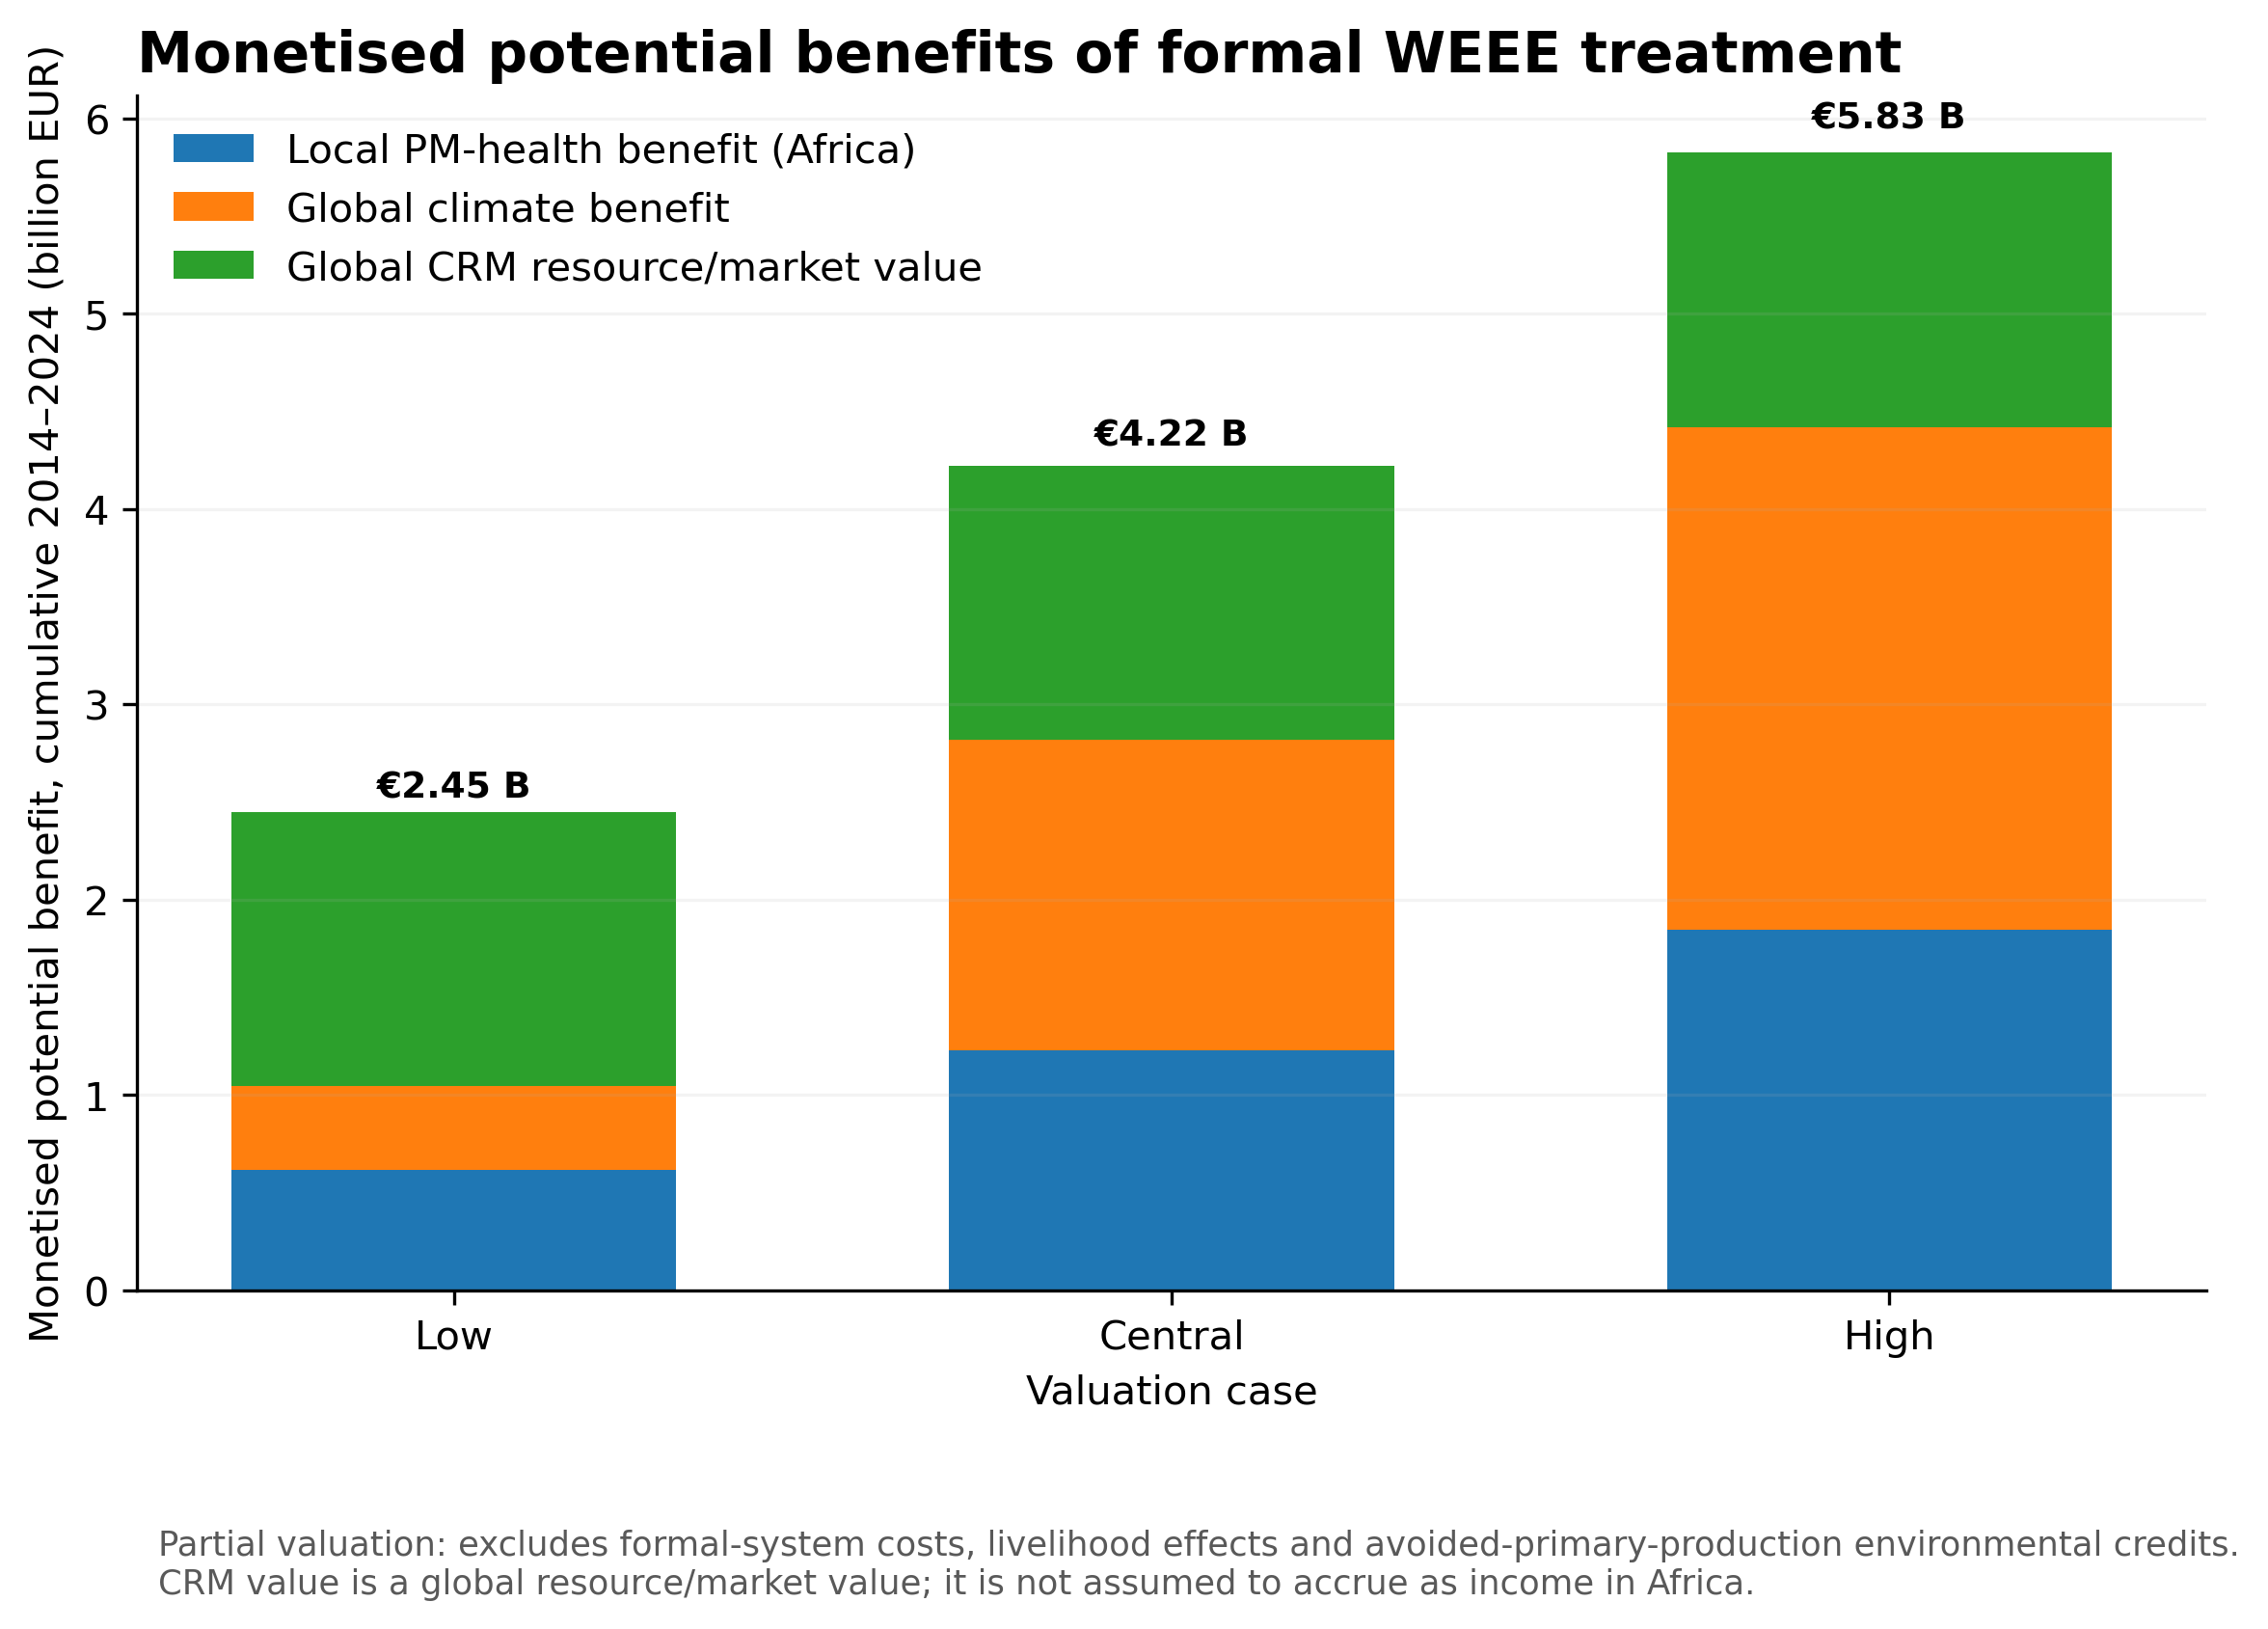

In [11]:
# CELL 11 — FIGURE 6: PARTIAL BENEFIT VALUATION

plot=valuation.copy()
for c in ["Health_local_EUR","Climate_global_EUR","CRM_global_resource_value_EUR"]:
    plot[c+"_bn"]=plot[c]/1e9

fig,ax=plt.subplots(figsize=(8.5,5.8),dpi=300)

x=np.arange(len(plot))
bottom=np.zeros(len(plot))

components=[
    ("Health_local_EUR_bn","Local PM-health benefit (Africa)"),
    ("Climate_global_EUR_bn","Global climate benefit"),
    ("CRM_global_resource_value_EUR_bn","Global CRM resource/market value"),
]
for col,label in components:
    ax.bar(x,plot[col],bottom=bottom,label=label,width=.62)
    bottom += plot[col].values

ax.set_xticks(x)
ax.set_xticklabels(plot["Valuation_case"])
ax.set_ylabel(f"Monetised potential benefit, cumulative {YEAR0}–{YEAR1} (billion EUR)")
ax.set_xlabel("Valuation case")
ax.set_title("Monetised potential benefits of formal WEEE treatment",
             loc="left",fontsize=14,weight="bold")
ax.legend(frameon=False)
ax.grid(axis="y",alpha=.15)

for i,total in enumerate(bottom):
    ax.text(i,total*1.015,f"€{total:.2f} B",ha="center",va="bottom",fontsize=9,weight="bold")

ax.text(
    .01,-.20,
    "Partial valuation: excludes formal-system costs, livelihood effects and avoided-primary-production environmental credits.\n"
    "CRM value is a global resource/market value; it is not assumed to accrue as income in Africa.",
    transform=ax.transAxes,fontsize=8.5,color=".35",va="top"
)

plt.tight_layout()
plt.savefig(FIG_DIR/"Figure6_monetised_benefits.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure6_monetised_benefits.pdf",bbox_inches="tight")
plt.show()

# Figure 7 — Spatial distribution of local health benefit

For the paper's local-vs-global argument, this optional figure shows where the monetised **local health benefit** of formalisation would occur. It uses the central €100k/DALY valuation only.

Climate and CRM are not allocated to African countries because they are treated as global benefits in this framing.

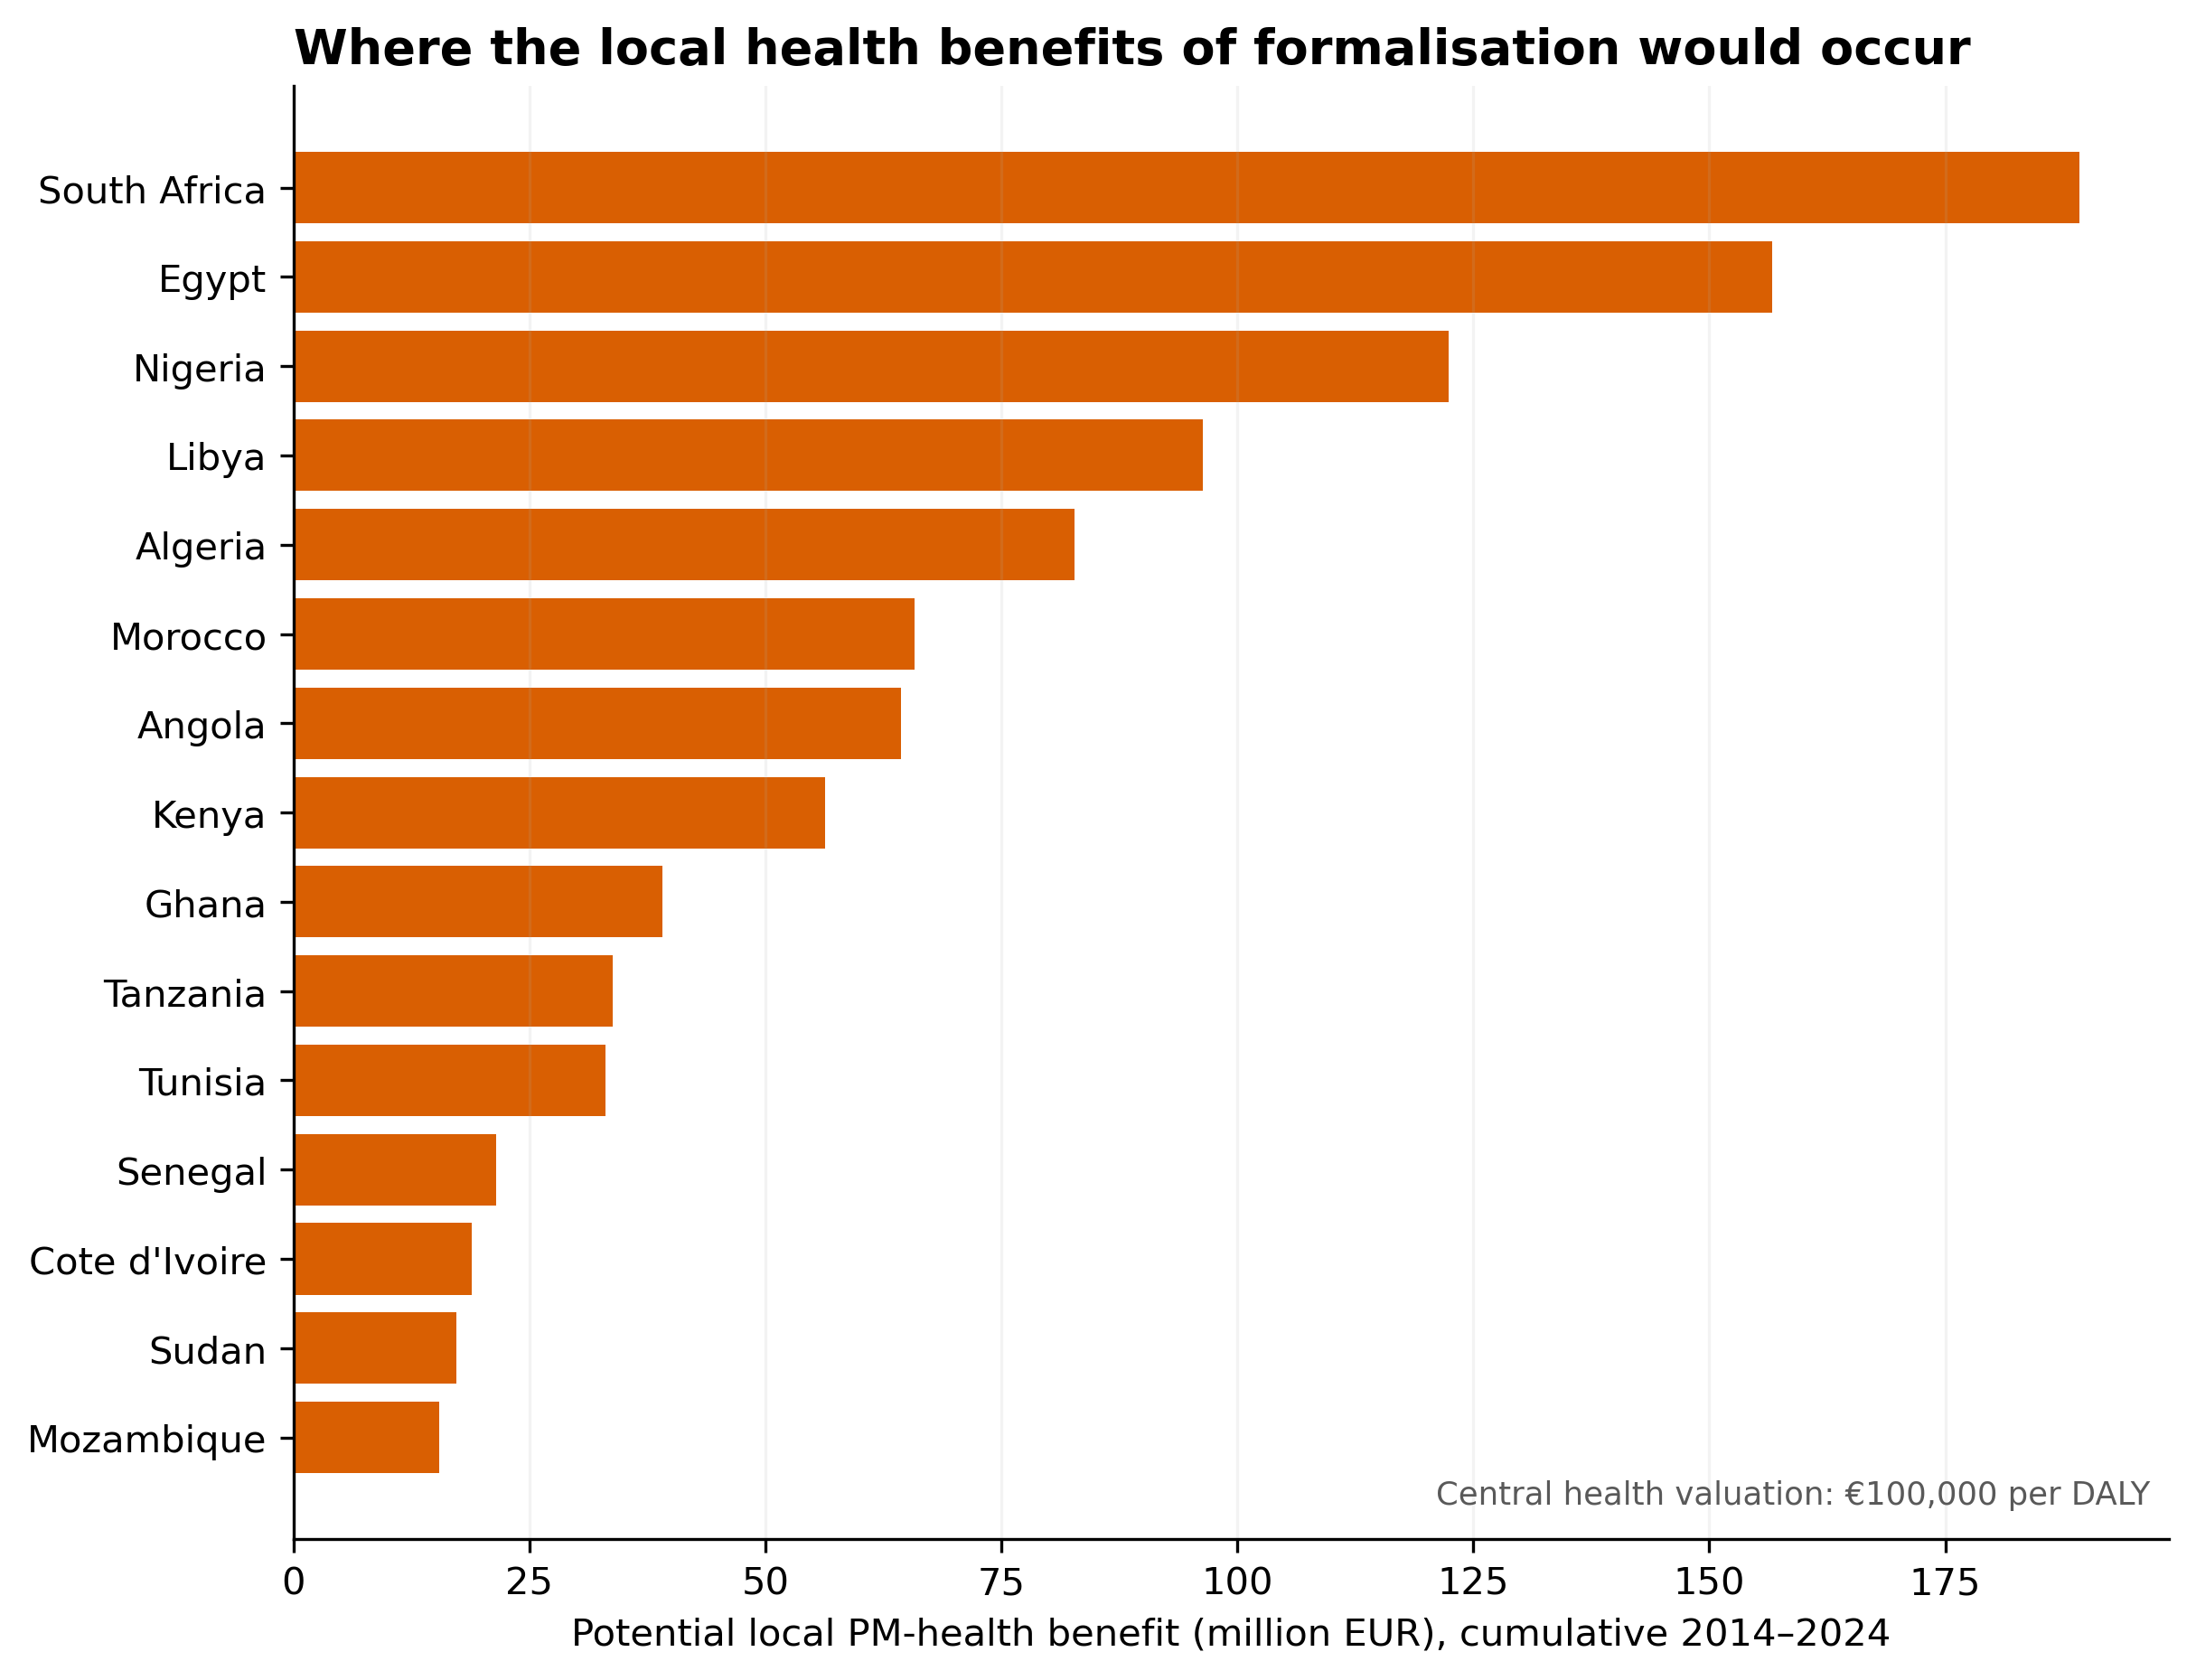

In [12]:
# CELL 12 — FIGURE 7: COUNTRY-LEVEL LOCAL HEALTH BENEFIT

cur=country_lcia[country_lcia["Scenario"]==S_CURRENT][["ISO3","Country","Year","PM_DALY"]].copy()
for_=country_lcia[country_lcia["Scenario"]==S_FORMAL][["ISO3","Country","Year","PM_DALY"]].copy()

cc=cur.merge(for_,on=["ISO3","Country","Year"],suffixes=("_current","_formal"))
cc["DALY_reduction"]=cc["PM_DALY_current"]-cc["PM_DALY_formal"]
country_benefit=cc.groupby(["ISO3","Country"],as_index=False)["DALY_reduction"].sum()
country_benefit["Health_benefit_EUR"]=country_benefit["DALY_reduction"]*HEALTH_VALUE_EUR_PER_DALY["Central"]
country_benefit["Health_benefit_mEUR"]=country_benefit["Health_benefit_EUR"]/1e6

top=country_benefit.nlargest(15,"Health_benefit_mEUR").sort_values("Health_benefit_mEUR")

fig,ax=plt.subplots(figsize=(8.2,6.3),dpi=300)
ax.barh(top["Country"],top["Health_benefit_mEUR"],color="#D95F02")
ax.set_xlabel(f"Potential local PM-health benefit (million EUR), cumulative {YEAR0}–{YEAR1}")
ax.set_title("Where the local health benefits of formalisation would occur",
             loc="left",fontsize=13,weight="bold")
ax.text(.99,.02,"Central health valuation: €100,000 per DALY",
        transform=ax.transAxes,ha="right",va="bottom",fontsize=8.5,color=".35")
ax.grid(axis="x",alpha=.15)
plt.tight_layout()
plt.savefig(FIG_DIR/"Figure7_local_health_benefit_country.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure7_local_health_benefit_country.pdf",bbox_inches="tight")
plt.show()

country_benefit.to_csv(TABLE_DIR/"country_local_health_benefit_central.csv",index=False)

# Headline results for manuscript

The output below is the preferred numerical source for the next manuscript revision. It replaces manually copied values from the old monolithic model.

In [13]:
# CELL 13 — HEADLINE RESULTS TABLE

ew_2024=ewaste.loc[ewaste["Year"]==YEAR1,"EWasteGenerated_kg"].sum()/1e9
ew_cum=ewaste["EWasteGenerated_kg"].sum()/1e9

central_val=valuation.set_index("Valuation_case").loc["Central"]

rows=[
    ["WEEE generated in final year",ew_2024,"Mt yr-1","Physical","Notebook 02"],
    ["Cumulative WEEE generated",ew_cum,"Mt","Physical","Notebook 02"],
    ["PM-health burden, current informal management",lca_sum.loc[S_CURRENT,"PM_DALY"],"DALY","Local","Notebook 03"],
    ["Potential PM-health reduction under formal treatment",delta_daly,"DALY","Local","Notebook 03"],
    ["GWP, current informal management",lca_sum.loc[S_CURRENT,"GWP_kgCO2eq"]/1e9,"Mt CO2-eq","Global","Notebook 03"],
    ["Potential GWP reduction under formal treatment",delta_tco2/1e6,"Mt CO2-eq","Global","Notebook 03"],
    ["Central monetised local health benefit",central_val["Health_local_EUR"]/1e9,"billion EUR","Local","Notebook 06 valuation"],
    ["Central monetised global climate benefit",central_val["Climate_global_EUR"]/1e9,"billion EUR","Global","Notebook 06 valuation"],
    ["CRM additional recovery market value",central_val["CRM_global_resource_value_EUR"]/1e9,"billion EUR","Global resource value","Notebook 06 valuation"],
    ["Central total partial monetised benefit",central_val["Total_partial_benefit_EUR"]/1e9,"billion EUR","Local + global","Notebook 06 valuation"],
]
headline=pd.DataFrame(rows,columns=["Quantity","Value","Unit","Spatial_interpretation","Source"])
headline.to_csv(TABLE_DIR/"headline_results.csv",index=False)
display(headline)

,Quantity,Value,Unit,Spatial_interpretation,Source
0,WEEE generated in final year,1.939478,Mt yr-1,Physical,Notebook 02
1,Cumulative WEEE generated,16.927311,Mt,Physical,Notebook 02
2,"PM-health burden, current informal management",15235.986580,DALY,Local,Notebook 03
3,Potential PM-health reduction under formal tre...,12304.571058,DALY,Local,Notebook 03
4,"GWP, current informal management",11.773108,Mt CO2-eq,Global,Notebook 03
5,Potential GWP reduction under formal treatment,8.578201,Mt CO2-eq,Global,Notebook 03
6,Central monetised local health benefit,1.230457,billion EUR,Local,Notebook 06 valuation
7,Central monetised global climate benefit,1.586967,billion EUR,Global,Notebook 06 valuation
8,CRM additional recovery market value,1.406112,billion EUR,Global resource value,Notebook 06 valuation
9,Central total partial monetised benefit,4.223537,billion EUR,Local + global,Notebook 06 valuation


# Recommended Q1 manuscript figure hierarchy

### Main text
1. **Figure 1 — EEE imports and WEEE generation**
2. **Figure 2 — Africa map of WEEE generation**
3. **Figure 3 — Local health vs global climate consequences**
4. **Figure 4 — Product-group drivers**
5. **Figure 5 — CRM physical availability and additional recovery**
6. **Figure 6 — Monetised potential benefits of formalisation**

### Candidate Supplementary
- Figure 7 — country-level monetised local health benefit.
- Detailed Low/Central/High recovery tables from Notebook 05.
- Electricity-intermittency sensitivity remains in Notebook 02 diagnostics and is **not** promoted as a paper figure here.

## Terminology

Use:
- current informal-management baseline;
- formal-treatment counterfactual;
- potential reduction under formal treatment;
- additional recoverable CRM;
- local health benefit;
- global climate benefit;
- global CRM resource/market value;
- partial monetised benefit / screening economic valuation.

Avoid:
- confidence intervals for the CRM Low/High screening cases;
- claiming CRM market value is African income;
- claiming a full CBA or benefit-cost ratio before formal-system costs are included;
- adding avoided-primary-production credits at this stage.

## Publication note — commodity prices and currency conversion

CRM valuation uses historical international reference prices rather than a current spot quotation.

- **Cu, Au and Ag:** World Bank *Commodity Price Data (Pink Sheet)* / corresponding international benchmark series.
- **Pd:** USGS platinum-group-metals annual-average market-price statistics.
- **Currency conversion:** ECB annual-average USD/EUR reference exchange rate, series `EXR.A.USD.EUR.SP00.A`.

For every year from **2014 through 2024**, the annual USD commodity price is converted to EUR using the ECB annual-average exchange rate for that same year. The central CRM reference price is then the arithmetic mean of the resulting eleven annual EUR/kg observations.

This is a historical **nominal market-value** convention. The notebook therefore does not label these values as constant EUR2024. The valuation is intended as a transparent screening translation of physical CRM recovery potential into international market value.

CRM value remains conceptually global: the model does not assume that the full market value would be captured within Africa.

In [14]:
# ============================================================
# FINAL PUBLICATION EXPORT — ALL RESULTS FOR PAPER REVIEW
# ============================================================

EXPORT_FILE = TABLE_DIR / "ALL_RESULTS_FOR_PAPER_REVIEW_FINAL.xlsx"

# WEEE summaries
ewaste_africa_product = (
    ewaste.groupby(["Year","ProductGroup"], as_index=False)["EWasteGenerated_kg"].sum()
)
ewaste_africa_product["EWaste_Mt"] = ewaste_africa_product["EWasteGenerated_kg"] / 1e9

ewaste_country = (
    ewaste.groupby(["ISO3","Country"], as_index=False)["EWasteGenerated_kg"].sum()
)
ewaste_country["EWaste_Mt"] = ewaste_country["EWasteGenerated_kg"] / 1e9
ewaste_country = ewaste_country.sort_values("EWasteGenerated_kg", ascending=False)

# CRM economic value by metal
crm_economic = pd.DataFrame({
    "CRM": list(crm_value_by_metal.keys()),
    "Additional_recoverable_kg": [crm_physical_kg[m] for m in crm_value_by_metal],
    "Historical_mean_price_EUR_per_kg": [CRM_PRICE_EUR_PER_KG[m] for m in crm_value_by_metal],
    "Resource_market_value_EUR": [crm_value_by_metal[m] for m in crm_value_by_metal],
})
crm_economic["Resource_market_value_million_EUR"] = (
    crm_economic["Resource_market_value_EUR"] / 1e6
)

# Transparent assumption table
assumptions = []

for case, value in HEALTH_VALUE_EUR_PER_DALY.items():
    assumptions.append({
        "Parameter":"Value per DALY","Case":case,"Value":value,
        "Unit":"EUR/DALY","Source_or_method":"Screening valuation scenario",
        "Spatial_interpretation":"Local PM-health benefit in Africa"
    })

for case, value in SCC_EUR_PER_TCO2.items():
    assumptions.append({
        "Parameter":"Social cost of carbon","Case":case,"Value":value,
        "Unit":"EUR/t CO2-eq",
        "Source_or_method":"Central anchored to Rennert et al. (2022); low/high screening cases",
        "Spatial_interpretation":"Global climate benefit"
    })

for metal, value in CRM_PRICE_EUR_PER_KG.items():
    source = crm_reference_prices.set_index("CRM").loc[metal, "Commodity_price_source"]
    assumptions.append({
        "Parameter":f"{metal} CRM reference price",
        "Case":"Mean annual price, 2014–2024","Value":value,
        "Unit":"EUR/kg",
        "Source_or_method":f"{source}; annual FX: ECB EXR.A.USD.EUR.SP00.A",
        "Spatial_interpretation":"Global resource / market value"
    })

assumptions = pd.DataFrame(assumptions)

# Publication-audit summary
audit = pd.DataFrame([
    ["Observation period", f"{YEAR0}–{YEAR1}", "Physical model"],
    ["Electricity intermittency baseline", bool(meta02.get("apply_electricity_adjustment")), "Notebook 02"],
    ["Avoided primary production credits included", bool(meta03.get("avoided_primary_production_credits_included")), "Notebook 03"],
    ["Monetization inside physical LCA", bool(meta03.get("monetization_included")), "Notebook 03"],
    ["CRM recovery subset", ", ".join(sorted(meta05.get("crm_codes_with_recovery_scenarios", []))), "Notebook 05"],
    ["CRM price period", "2014–2024", "Notebook 06"],
    ["CRM annual FX method", "Same-year ECB annual-average USD/EUR", "Notebook 06"],
    ["CRM interpretation", "Global resource / market value; not African income", "Notebook 06"],
    ["Avoided-primary environmental benefits monetised", "No", "Notebook 06"],
    ["Formal-system CAPEX/OPEX included", "No", "Notebook 06"],
], columns=["Check","Value","Source"])

with pd.ExcelWriter(EXPORT_FILE, engine="openpyxl") as writer:
    headline.to_excel(writer, sheet_name="00_HEADLINE_RESULTS", index=False)
    audit.to_excel(writer, sheet_name="01_PUBLICATION_AUDIT", index=False)
    assumptions.to_excel(writer, sheet_name="02_ASSUMPTIONS", index=False)
    valuation.to_excel(writer, sheet_name="03_ECON_VALUATION", index=False)

    crm_economic.to_excel(writer, sheet_name="04_CRM_ECONOMIC", index=False)
    crm_reference_prices.to_excel(writer, sheet_name="05_CRM_PRICE_MEANS", index=False)
    crm_price_history.to_excel(writer, sheet_name="06_CRM_PRICE_HISTORY", index=False)

    crm_available_cum.to_excel(writer, sheet_name="07_CRM_AVAILABLE", index=False)
    crm_additional.to_excel(writer, sheet_name="08_CRM_RECOVERY", index=False)

    africa_lcia.to_excel(writer, sheet_name="09_AFRICA_LCIA", index=False)
    country_lcia.to_excel(writer, sheet_name="10_COUNTRY_LCIA", index=False)
    product_lcia.to_excel(writer, sheet_name="11_PRODUCT_LCIA", index=False)
    comparison.to_excel(writer, sheet_name="12_FORMAL_VS_INFORMAL", index=False)

    country_benefit.to_excel(writer, sheet_name="13_COUNTRY_HEALTH", index=False)
    ewaste_africa_product.to_excel(writer, sheet_name="14_WEEE_PRODUCT", index=False)
    ewaste_country.to_excel(writer, sheet_name="15_WEEE_COUNTRY", index=False)
    ewaste.to_excel(writer, sheet_name="16_WEEE_FULL", index=False)

print("="*76)
print("FINAL PUBLICATION REVIEW FILE CREATED")
print("="*76)
print(EXPORT_FILE)

print("\nHEADLINE RESULTS")
display(headline)

print("\nECONOMIC VALUATION")
display(valuation)

print("\nFINAL HISTORICAL CRM REFERENCE PRICES")
display(
    crm_reference_prices[
        ["CRM","Mean_EUR_per_kg","Commodity_price_source","FX_source"]
    ].sort_values("CRM")
)

print("\nCRM ECONOMIC VALUE")
display(crm_economic)

print("\nPUBLICATION AUDIT")
display(audit)

FINAL PUBLICATION REVIEW FILE CREATED
C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\06_paper_outputs\tables\ALL_RESULTS_FOR_PAPER_REVIEW_FINAL.xlsx

HEADLINE RESULTS


,Quantity,Value,Unit,Spatial_interpretation,Source
0,WEEE generated in final year,1.939478,Mt yr-1,Physical,Notebook 02
1,Cumulative WEEE generated,16.927311,Mt,Physical,Notebook 02
2,"PM-health burden, current informal management",15235.986580,DALY,Local,Notebook 03
3,Potential PM-health reduction under formal tre...,12304.571058,DALY,Local,Notebook 03
4,"GWP, current informal management",11.773108,Mt CO2-eq,Global,Notebook 03
5,Potential GWP reduction under formal treatment,8.578201,Mt CO2-eq,Global,Notebook 03
6,Central monetised local health benefit,1.230457,billion EUR,Local,Notebook 06 valuation
7,Central monetised global climate benefit,1.586967,billion EUR,Global,Notebook 06 valuation
8,CRM additional recovery market value,1.406112,billion EUR,Global resource value,Notebook 06 valuation
9,Central total partial monetised benefit,4.223537,billion EUR,Local + global,Notebook 06 valuation



ECONOMIC VALUATION


,Valuation_case,Health_local_EUR,Climate_global_EUR,CRM_global_resource_value_EUR,Total_partial_benefit_EUR
0,Low,6.152286e+08,4.289100e+08,1.406112e+09,2.450251e+09
1,Central,1.230457e+09,1.586967e+09,1.406112e+09,4.223537e+09
2,High,1.845686e+09,2.573460e+09,1.406112e+09,5.825258e+09



FINAL HISTORICAL CRM REFERENCE PRICES


,CRM,Mean_EUR_per_kg,Commodity_price_source,FX_source
0,Ag,568.764786,World Bank Pink Sheet / international silver b...,ECB EXR.A.USD.EUR.SP00.A
1,Au,44837.396092,World Bank Pink Sheet / international gold ben...,ECB EXR.A.USD.EUR.SP00.A
2,Cu,6.259715,World Bank Pink Sheet / international copper b...,ECB EXR.A.USD.EUR.SP00.A
3,Pd,37878.773566,USGS platinum-group-metals annual-average mark...,ECB EXR.A.USD.EUR.SP00.A



CRM ECONOMIC VALUE


,CRM,Additional_recoverable_kg,Historical_mean_price_EUR_per_kg,Resource_market_value_EUR,Resource_market_value_million_EUR
0,Cu,1.198913e+08,6.259715,7.504855e+08,750.485462
1,Ag,2.958895e+04,568.764786,1.682915e+07,16.829152
2,Au,1.188096e+04,44837.396092,5.327115e+08,532.711512
3,Pd,2.800675e+03,37878.773566,1.060861e+08,106.086148



PUBLICATION AUDIT


,Check,Value,Source
0,Observation period,2014–2024,Physical model
1,Electricity intermittency baseline,True,Notebook 02
2,Avoided primary production credits included,False,Notebook 03
3,Monetization inside physical LCA,False,Notebook 03
4,CRM recovery subset,"Ag, Au, Cu, Pd",Notebook 05
5,CRM price period,2014–2024,Notebook 06
6,CRM annual FX method,Same-year ECB annual-average USD/EUR,Notebook 06
7,CRM interpretation,Global resource / market value; not African in...,Notebook 06
8,Avoided-primary environmental benefits monetised,No,Notebook 06
9,Formal-system CAPEX/OPEX included,No,Notebook 06
